# 10 Requirement map: the support every cost sample needs, without solving ReEDS

**Purpose.** This notebook fits the *requirement map* and applies it to the whole Monte Carlo
ensemble. The requirement map is a regression that predicts the mandate's *shadow price* (the
extra system cost of the marginal mandated SMR that the market does not pay back) for any *cost
sample* (one joint Monte Carlo draw of the SMR cost world; 10,000 per target trajectory) and any
*online year* (the year new capacity enters service; `t` or "build year" in the code), without
solving ReEDS. The map then converts that shadow price into the *Equivalent ITC* (the
investment-tax-credit rate, as a share of capital cost, that would pay the same support; "rate" in
the code). The map is fitted on 66 ReEDS-solved cost samples, 11 per *target trajectory* (a
published national path of mandated SMR capacity; "schedule" in the code: `eia`, `aj`, `iaea`,
`mck`, `cop28`, `eo`). The notebook certifies the fit by leave-one-out, derives the error band E7,
and writes the fans, masks and bills that Figs. 3 and 4, Table 2 and Supplementary Figs. 20–22 and
Supplementary Tables 6, 10 and 13 show. It also computes the construction-duration floor
sensitivity (Supplementary Table 6), because that table needs this map's dollar slope and
conversion factors.

**Inputs.**
- `results/exports/01/mc_perdraw.npz` and `engine_constants.json` (notebook 01_monte_carlo_cost_engine):
  the 10,000 cost samples per trajectory and the cost engine's constants.
- `results/exports/07/{t01_case_inventory, t08_rental_transfer, t09_required_itc, t12_fiscal_comparison}.csv`
  (notebook 07_required_support): the exact required rate of the 30 production anchors, the
  mandate capacities, the rental transfer and the published credit outlays.
- `results/exports/06a/step3_checks/duals_by_year.csv` (notebook 06a_run_tables_core): the
  mandate path and the dual of every production run.
- `results/exports/06b/rate_design2_checks/t09_required_itc_port_anchors.csv` (notebook
  06b_run_tables_rate_design): the exact required rate of the 36 map anchors.
- `data/registration/smr100/selected_draws{,_p25p75}.csv`, `data/registration/ratedesign2/m01_map_anchor_spec.csv`,
  `data/registration/batch3/b3_run_spec.csv`: which draw each solved sample is.
- ReEDS inputs of this fork: `inputs/financials/{financials_sys_ATB2024, inflation_default,
  construction_schedules_mc, construction_times_mc_<case>, financials_tech_mc_<case>}.csv`,
  `inputs/plant_characteristics/{nuclear-smr_ATB_2024_*, nuclear_ATB_2024_*, nuclear-smr_mc_<case>}.csv`.

**Outputs.** `results/exports/10/`: `m100_loo_cells`, `m101_loo_summary`, `m102_selection`,
`m102b_chosen_coefficients`, `m102c_dollar_slopes`, `m103_band_e7`, `m103b_conversion_factors`,
`m103c_split_test`, `m103d_nested_loo`, `m103e_conversion_only_loo`, `m103f_skw_accuracy`,
`m103g_schedule_year_bias`, `m103h_censored_cells`, `m103i_cheap_tail`, `m104_requirement_fans(_cut)`,
`m104b_per_world_requirements`, `m104c_shadow_price_fans`, `m105_feasibility_mask(_cut)`,
`m106_demonstration_gap(_cut)`, `m107_common_window_table`, `m108_verdict`,
`m109_batch3_anchor_predictions`, `m10b_population_rates.npz`, `m10c_bill_three_bases`,
`m10e_financed_bill`, `table2_display`, `duration_floor_sensitivity` (all `.csv` unless named),
`requirement_map_metadata.json`, and the figure sources `n104c_shadow_price_fans.png` (Fig. 3),
`n105_rate_fans_pct.png` and `n106_mask_paper.png` (Fig. 4), `n104_dollar_fans_cut.png` (SF21).
`results/figures/si/`: `SF20_1_loo_pred_vs_true.png`, `SF20_2_error_bands.png`,
`SF21_credit_denominated_gap.png`, `SF22_demonstration_gap.png`.

**Paper items.** Fig. 3 (source n104c, m104c), Fig. 4 (sources n105, n106; m104–m107, m103, m103i),
Table 2 (m10e, `table2_display`), Supplementary Figs. 20–22, Supplementary Table 6
(`duration_floor_sensitivity`), Supplementary Table 10 (m101, m102, m102c, m103, m103f, m103i),
Supplementary Table 13 (m104, m105, m106, m107, m103), Supplementary Note 5 (m108, m101, m102, m103).
Later notebooks read `m104`, `m104c`–`m107`, `m108`, `m109`, `m10b` (11_market_transfer) and
`m104`, `m108` (15_new_plant_value); notebook 16 composes Figs. 3 and 4 and re-exports the tables.

**Runtime.** About 11 minutes on this machine with 4 BLAS threads (the nested leave-one-out of
section 4 takes most of it). Run it alone: the leave-one-out loops are least-squares fits, and a
different thread count can change their last digits.

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4, seed_note="figure jitter in SF20b uses numpy default_rng(i), i = the trajectory's index 0-5; no other randomness")

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.
seeds: figure jitter in SF20b uses numpy default_rng(i), i = the trajectory's index 0-5; no other randomness


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': "figure jitter in SF20b uses numpy default_rng(i), i = the trajectory's index 0-5; no other randomness"}

## 1. Inputs, conventions and the solved samples

The next cell loads the ensemble, the 66 solved samples and their exact required rates. It fixes
the registered constants of the map (methods register v2.4 to v2.9):

- `TOL_SHORT` = 0.01 is the registered *delivery cushion*: one rate point that the fans and masks
  subtract from each requirement, because the credit that delivers the build lies slightly below the
  shadow-price requirement.
- `DISPLAY_CUT` = 0.03 is the paper's *display allowance*: the figures subtract three points instead
  of one. Every `_cut` export is the three-point twin of the registered one-point export.
- `W_COMMON` = 2038 is the *common window* end that Fig. 4 and Table 2 use. The paper justifies
  2038 by the bimodality of the requirement across the samples; nothing in this notebook optimizes it.
- `CAPS` are the statutory credit ceilings the masks test: 50% (today's stacked maximum) and 60%.

**Units.** The shadow price is `S_kw`, the *capitalized* shadow price in 2024 $/kW: the annual dual
(2004 $/MW-yr) times the ReEDS O&M present-value factor, converted with `TO2024` = 1.6590. This is
the *financed basis*: dollars per kW of the plant's financed capital cost, before any conversion to a
tax credit. The exports keep 2024 dollars. The figures show 2025 dollars through `ps.to2025(2024)`.

**The discount rate.** `DR` is the mean post-2026 ReEDS system real rate, 5.36%. The cell asserts it.

In [2]:
import json
from itertools import combinations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
import numpy as np
import pandas as pd

from nlpaper import mapfit as mf
from nlpaper import compose

pd.set_option("display.width", 220)

EXPORTS = paths.exports("10")                   # every CSV / npz and the main-figure source PNGs
EXP01, EXP07 = paths.exports("01"), paths.exports("07")
CHECKS3 = paths.exports("06a") / "step3_checks"
RD2_CHECKS = paths.exports("06b") / "rate_design2_checks"
REG = paths.DATA / "registration"
B3_SPEC = REG / "batch3" / "b3_run_spec.csv"
FIN_DIR = paths.reeds_inputs() / "financials"
PC_DIR = paths.reeds_inputs() / "plant_characteristics"
paths.require(EXP01 / "mc_perdraw.npz", "notebook 01_monte_carlo_cost_engine")
paths.require(EXP07 / "t09_required_itc.csv", "notebook 07_required_support")
paths.require(CHECKS3 / "duals_by_year.csv", "notebook 06a_run_tables_core")
paths.require(RD2_CHECKS / "t09_required_itc_port_anchors.csv", "notebook 06b_run_tables_rate_design")

# ---- registered constants (methods register v2.4 / v2.7 / v2.8 / v2.9) ---------------------
TOL_SHORT = 0.01            # the delivery cushion (statutory rate points)
DISPLAY_CUT = 0.03          # the paper display allowance; display twins only
CAPS = [0.50, 0.60]
W_PRIMARY = 2035            # the registered demonstration window (kill tests KB1/KB2)
W_SENS = 2033
W_COMMON = 2038             # the paper's common window end (Fig 4, Table 2)
QS = [5, 25, 50, 75, 95]
MODEL_YEARS = [2031, 2032, 2033, 2034, 2035, 2038, 2041, 2044, 2047, 2050]
TO2024 = 1.6590             # 2004 $ -> 2024 $ (ITC calculation procedure, step 8)
N_HIDE = 2                  # exhaustive split test: all C(11, 2) = 55 two-sample hide-sets per trajectory
GM2_TOL, GM2_MIN_PICKS = 0.25, 60
ACCEPT9 = {"ct": dict(mae=0.93, p90=2.39, mx=8.4, mae_kw=43.4), "cc": dict(mae=0.94, p90=2.27, mx=8.7, mae_kw=45.3)}   # registered before the fit (methods v2.9)
SCHEDULES = mf.SCHEDULES
AB2TOK = mf.AB2TOK
GREY = "0.35"
VERDICT = []                # (kind, name, result, detail) -> m108

# ---- the MC ensemble ----------------------------------------------------------------
Z = np.load(EXP01 / "mc_perdraw.npz")
META = json.loads(str(Z["meta_json"]))
assert META["n_draws"] == 10000 and META["master_seed"] == 20260715, META
N_DRAWS = META["n_draws"]
YI = {int(y): i for i, y in enumerate(Z["years"])}
TOK2AB = {v: k for k, v in AB2TOK.items()}
NAME2AB = {str(n): TOK2AB[str(t)] for n, t in zip(Z["sched_order"], Z["scen_tokens"])}
WCOLS = [str(c) for c in Z["world_columns"]]

# ---- the 30 solved anchors + the 36 map anchors = 66 (as v2 / v4) ------------------------
reg = pd.concat([pd.read_csv(REG / "smr100" / "selected_draws.csv"),
                 pd.read_csv(REG / "smr100" / "selected_draws_p25p75.csv")], ignore_index=True)
reg["ab"] = reg["schedule"].map(NAME2AB)
reg["case"] = "smr100_" + reg["ab"] + "_" + reg["percentile"]
assert len(reg) == 30 and reg["case"].is_unique, "30 production anchors: 6 trajectories x P5/P25/P50/P75/P95"
ANCH = {ab: {} for ab in SCHEDULES}
for r in reg.itertuples():
    ANCH[r.ab][r.percentile] = int(r.draw_index)
ANCHORS30 = reg[["case", "ab", "draw_index"]].copy()
m01 = pd.read_csv(REG / "ratedesign2" / "m01_map_anchor_spec.csv")
ANCHORS_MA = m01[["run", "ab", "draw_index"]].rename(columns={"run": "case"})
ANCHORS66 = pd.concat([ANCHORS30, ANCHORS_MA], ignore_index=True)
assert len(ANCHORS66) == 66 and ANCHORS66["case"].is_unique, "66 solved samples = 30 production anchors + 36 map anchors"
MA_CASES = list(ANCHORS_MA["case"])
DRAW_OF = {r.case: int(r.draw_index) for r in ANCHORS66.itertuples()}
AB_OF = {r.case: r.ab for r in ANCHORS66.itertuples()}

# ---- the required-rate tables: frozen t09 (30 anchors) + the ported chain (36 map anchors) ---
t09_frz = pd.read_csv(EXP07 / "t09_required_itc.csv")
t09_ma = pd.read_csv(RD2_CHECKS / "t09_required_itc_port_anchors.csv")
t09_66 = pd.concat([t09_frz[t09_frz["case"].isin(ANCHORS30["case"])], t09_ma], ignore_index=True)
assert t09_66["case"].nunique() == 66
t09r = t09_66[t09_66["status"] == "rate"].set_index(["case", "t"])["i_model_headline"]
S_2004 = t09_66[t09_66["status"] == "rate"].set_index(["case", "t"])["S_t_2004_per_MW"]
CCM_T09 = t09_66[t09_66["status"] == "rate"].set_index(["case", "t"])["ccmult"]
CENS_CELLS = {(r["case"], int(r["t"])) for _, r in
              t09_66[t09_66["itc_insufficient"].fillna(False).astype(bool)].iterrows()}
CENSORED = {(AB_OF[c], t) for (c, t) in CENS_CELLS}
SLACK_CELLS = {(r["case"], int(r["t"])) for _, r in t09_66[t09_66["status"].str.startswith("slack")].iterrows()}

def rate_of(case, t):
    v = t09r.get((case, t), 0.0)
    return float(v) if np.isfinite(v) else 0.0

# ---- dollars, discount rate, mandate additions (rate_design v2 machinery, verbatim) -------
sys_fin = pd.read_csv(FIN_DIR / "financials_sys_ATB2024.csv")
infl = pd.read_csv(FIN_DIR / "inflation_default.csv")
sys_fin = sys_fin.merge(infl, on="t", how="left")
sys_fin["d_nom"] = ((1 - sys_fin["debt_fraction"]) * (sys_fin["rroe_nom"] - 1)
                    + sys_fin["debt_fraction"] * (sys_fin["interest_rate_nom"] - 1)
                      * (1 - sys_fin["tax_rate"]) + 1)
sys_fin["d_real"] = sys_fin["d_nom"] / sys_fin["inflation_rate"]
_s = sys_fin.set_index("t")["d_real"].reindex(range(1990, 2051)).ffill()
DR = float(np.mean(_s.loc[np.arange(2026, 2051)].to_numpy(float)))   # 2026-09-22: the post-2026 ReEDS system real rate (5.36%); before 09-22 the 2010-2050 mean (4.55%), a history-year artefact
assert round(DR, 4) == 1.0536, f"the post-2026 ReEDS system real discount rate must be 5.36%, got {DR}"
_infl = infl.set_index("t")["inflation_rate"]
D2224 = float(_infl.loc[2023] * _infl.loc[2024])
assert 1.0 < D2224 < 1.2, D2224

# ---- the v2.8 inputs: ReEDS's construction-financing multiplier, the whole-year rule, FOM ------
_ib = sys_fin.set_index("t")["interest_rate_nom"].reindex(range(1990, 2051)).ffill()
IB = {t: float(_ib.loc[t]) for t in MODEL_YEARS}
CS = pd.read_csv(FIN_DIR / "construction_schedules_mc.csv")
CCT = {t: mf.ccmult_table(CS, IB[t]) for t in MODEL_YEARS}          # {year: {construction years: ccmult}}
ATB30 = {s: pd.read_csv(PC_DIR / f"nuclear-smr_ATB_2024_{s}.csv").set_index("t").loc[2030] for s in ("advanced", "conservative")}
FOM_LO, FOM_HI = float(ATB30["advanced"]["fom"]), float(ATB30["conservative"]["fom"])
assert (float(ATB30["advanced"]["capcost"]), float(ATB30["conservative"]["capcost"])) == (5500.0, 10000.0)
_atbL = {s: pd.read_csv(PC_DIR / f"nuclear_ATB_2024_{s}.csv").set_index("t").loc[2030, "capcost"] for s in ("advanced", "conservative")}
assert (float(_atbL["advanced"]), float(_atbL["conservative"])) == mf.BOAK_LARGE_RANGE, _atbL

def add_v5_inputs(df, ab):
    '''The world as ReEDS receives it, for rows (w, t) of one schedule: construction years by the
    case-export rule, FOM by the anchor-cost dial, ccmult by the (years, year) lookup.'''
    dur, world = Z[f"dur_{AB2TOK[ab]}_smr"], Z[f"worlds_{AB2TOK[ab]}"]
    w, t = df["w"].to_numpy(int), df["t"].to_numpy(int)
    df["ct_yrs"] = mf.construction_years(dur[w, [YI[x] for x in t]])
    df["fom"] = mf.fom_of_world(world[w, WCOLS.index("boak_large")], FOM_LO, FOM_HI)
    df["ccmult"] = [CCT[int(tt)][int(n)] for tt, n in zip(t, df["ct_yrs"])]
    return df

duals3 = pd.read_csv(CHECKS3 / "duals_by_year.csv")
FLOOR = duals3[duals3["t"] <= 2030].groupby("case")["mandate_MW"].max()
duals3["program_MW"] = (duals3["mandate_MW"] - duals3["case"].map(FLOOR).fillna(0.0)).clip(lower=0.0)
DCASE = {c: g.set_index("t") for c, g in duals3.groupby("case")}
t12 = pd.read_csv(EXP07 / "t12_fiscal_comparison.csv").set_index("case")
print(f"setup: 66 anchors ({len(t09r)} rate cells, {len(CENS_CELLS)} censored, {len(SLACK_CELLS)} slack cells); "
      f"D2224 {D2224:.5f}; DR {DR:.4f}")
print(f"interest base by model year: {sorted(set(IB.values()))}; ccmult by construction years (2031): "
      + ", ".join(f"{n} yr {v:.4f}" for n, v in CCT[2031].items() if n <= 7) + f"; FOM range {FOM_LO}-{FOM_HI} $/kW-yr")

setup: 66 anchors (600 rate cells, 7 censored, 5 slack cells); D2224 1.07119; DR 1.0536
interest base by model year: [1.08]; ccmult by construction years (2031): 1 yr 1.0392, 2 yr 1.0642, 3 yr 1.0898, 4 yr 1.1254, 5 yr 1.1589, 6 yr 1.1917, 7 yr 1.2306; FOM range 118.0-216.0 $/kW-yr


## 2. Shared machinery: build years, additions, discounting, outlay pricing

For each target trajectory the next cell reads the mandated program path of the P5 production run
and derives the online years with new additions (`BUILD_TS`), the added MW per online year (`ADD`)
and the discount factor to 2026 at `DR` (`DISC`). `OCCW` holds each sample's own overnight capital
cost in 2024 $/kW. `IREF` is the exact required rate of the median (P50) production anchor, the
*reference credit path* of the fans.

`WPRICE` prices a credit offer into a present-value outlay in $B per ($/kW offered). Its
calibration `KAPPA` scales the simple additions-times-discount weight so that it reproduces the
published credit outlays of notebook 07 (t12) at the P5, P50 and P95 anchors. Gate G3 requires that
calibration to leave a residual of at most 7% at all 18 anchors.

`PLANE` places every sample in a two-dimensional cost plane (log 2031 cost, 2050-over-2031 cost
ratio). The density weights of the solved samples come from that plane; they enter only the
weighted 90th-percentile error of gate GM1′.

In [3]:
ADD, DISC, BUILD_TS, OCC22, OCCW, IREF, REFC = {}, {}, {}, {}, {}, {}, {}
KAPPA, KAP_RES, WPRICE = {}, {}, {}
for ab in SCHEDULES:
    d0 = DCASE[f"smr100_{ab}_p05"]
    build_ts = [int(t) for t in d0.index if t >= 2026 and d0.loc[t, "program_MW"] > 0]
    prog = np.array([d0.loc[t, "program_MW"] for t in build_ts])
    add = np.diff(prog, prepend=0.0).clip(min=0.0)
    disc = np.array([DR ** -(t - 2026) for t in build_ts])
    keep = add > 0
    BUILD_TS[ab] = [t for t, k in zip(build_ts, keep) if k]
    ADD[ab] = add[keep]
    DISC[ab] = disc[keep]
    occ = Z[f"occ_{AB2TOK[ab]}_smr"]
    occ_t = np.stack([occ[:, YI[t]] for t in BUILD_TS[ab]], axis=1)      # 2022 $/kW
    OCC22[ab] = occ_t
    OCCW[ab] = occ_t * D2224                                             # 2024 $/kW
    cases = {p: f"smr100_{ab}_{p}" for p in ["p05", "p50", "p95"]}
    IREF[ab] = np.array([rate_of(cases["p50"], t) for t in BUILD_TS[ab]])
    REFC[ab] = IREF[ab] * OCCW[ab][ANCH[ab]["p50"]]
    raw_own = {}
    for p in ["p05", "p50", "p95"]:
        w_ = ANCH[ab][p]
        i_own = np.array([rate_of(cases[p], t) for t in BUILD_TS[ab]])
        raw_own[p] = float(np.sum(i_own * OCCW[ab][w_] * ADD[ab] * DISC[ab]) * 1000 / 1e9)
    pub = {p: float(t12.loc[cases[p], "PV_ITC_outlay_2024B"]) for p in ["p05", "p50", "p95"]}
    KAPPA[ab] = float(np.mean([pub[p] / raw_own[p] for p in ["p05", "p50", "p95"]]))
    KAP_RES[ab] = max(abs(KAPPA[ab] * raw_own[p] / pub[p] - 1) for p in ["p05", "p50", "p95"])
    WPRICE[ab] = KAPPA[ab] * ADD[ab] * DISC[ab] * 1000 / 1e9   # $B per ($/kW offered)
assert all(BUILD_TS[ab] == [t for t in MODEL_YEARS if t in BUILD_TS[ab]] for ab in SCHEDULES)
G3 = all(KAP_RES[ab] <= 0.07 for ab in SCHEDULES)
assert G3, {ab: round(KAP_RES[ab], 3) for ab in SCHEDULES}
VERDICT.append(("gate", "G3", "PASS", "outlay calibration residual <= 7% at all 18 anchors (rate_design v2 machinery)"))

PLANE = {}
for ab in SCHEDULES:
    occ = Z[f"occ_{AB2TOK[ab]}_smr"]
    X = np.column_stack([np.log(occ[:, YI[2031]]), occ[:, YI[2050]] / occ[:, YI[2031]]])
    mu, sd = X.mean(0), X.std(0)
    PLANE[ab] = ((X - mu) / sd, mu, sd, X)
print("G3 PASS; build years:", {ab: (BUILD_TS[ab][0], BUILD_TS[ab][-1], len(BUILD_TS[ab])) for ab in SCHEDULES})

G3 PASS; build years: {'eia': (2038, 2050, 5), 'aj': (2031, 2050, 10), 'iaea': (2031, 2050, 10), 'mck': (2031, 2050, 10), 'cop28': (2031, 2050, 10), 'eo': (2031, 2050, 10)}


## 3. The fit (m100–m102): target, inputs, conversion, family, leave-one-out selection

**The target.** Each *cell* is one solved sample in one online year; there are 600 cells. The target
is the cell's capitalized shadow price `S_kw` (2024 $/kW).

**The inputs.** The map uses three numbers per cell, exactly as ReEDS receives them for that sample:
the overnight cost in the online year (`occ`); the construction duration in whole years (`ct_yrs`,
the case-export rule `round(months / 12)` clipped to 1–10); and the fixed O&M cost (`fom`, $/kW-yr).
Map v2.9 adds construction years × cost (`ct_x_occ`), the multiplicative form in which ReEDS applies
the duration. No learning-model parameter enters. The cell asserts that the inputs derived from each
sample's ensemble draw equal the input files that ReEDS read for the 66 solved samples.

**The conversion.** A predicted shadow price becomes an Equivalent ITC as
`rate = S_kw × c′ / (ccmult × occ24)`. `ccmult` is the sample's own *construction-financing
multiplier* (ReEDS's interest-during-construction factor for its construction years; the cell
asserts it against notebook 07's t09). `c′` is the *dollar-to-rate factor* of the trajectory and
online year: the geometric mean over the solved samples of `rate × occ24 × ccmult / S_kw`. The factor
absorbs which ReEDS region is marginal and the time-constant financing terms.

**The family.** Thirty ridge regressions (penalized least squares): M4 (the inputs plus trajectory,
year and trajectory × year intercepts), M5 (M4 plus trajectory-specific cost slopes), M5L (M5 plus
log-cost), and the same three with the interaction (M4X, M5X, M5LX), each at penalties 0.1, 0.3, 1, 3
and 10.

**Scoring and selection.** Leave-one-out means: hide one solved sample, fit on the other 65, predict
the hidden sample's shadow price, and convert it with the other samples' `c′` and the hidden
sample's own `ccmult`. The error is in rate points. The member with the smallest pooled mean
absolute error (MAE) wins; ties go to fewer inputs, then the smaller penalty. Before scoring, the
cell asserts the acceptance numbers registered in methods v2.9 (MAE 0.93, 90th percentile 2.39,
maximum 8.4 rate points, 43.4 $/kW for M5X at penalty 0.1).

`m100` holds every member's leave-one-out prediction for every cell; `m101` summarizes them (Supplementary
Table 10a reads the M5X rows). Two comparison rows stay in `m100`/`m101`: the earlier map's model form
(M3, penalty 0.3, nine inputs) refitted on the same 600 cells with both conversions, and the
ccmult × cost diagnostic M5XC. Neither is eligible for selection.

In [4]:
cells66 = mf.anchor_cells(t09_66, ANCHORS66, Z, YI)
assert cells66["case"].nunique() == 66 and int(cells66["censored"].sum()) == len(CENS_CELLS)
# v2.8.1: the t09 flag (exact rate > 100%) is kept as `over100`; `censored` (what the fold machinery
# excludes) is False everywhere -- the shadow price of those cells is exact.
cells66["over100"] = cells66["censored"].astype(bool)
cells66["censored"] = False
_idx = list(zip(cells66["case"], cells66["t"].astype(int)))
cells66["S_kw"] = S_2004.loc[_idx].to_numpy(float) * TO2024 / 1000.0
cells66["occ24"] = cells66["occ"] * D2224
assert (cells66["S_kw"] > 0).all() and (cells66["occ24"] > 0).all()
YEARS_ALL = sorted(int(t) for t in cells66["t"].unique())
assert YEARS_ALL == MODEL_YEARS

# the v2.8 inputs from the world's ensemble draw (the population rule) ...
cells66 = pd.concat([add_v5_inputs(g.copy(), ab) for ab, g in cells66.groupby("ab", sort=False)]).sort_index()
# ... asserted equal to the injected input files of the 66 solved worlds
_files = {}
for c in ANCHORS66["case"]:
    ct = pd.read_csv(FIN_DIR / f"construction_times_mc_{c}.csv")
    ct = ct[ct["i"].str.lower() == "nuclear-smr"].set_index("t_online")["construction_time"]
    pc = pd.read_csv(PC_DIR / f"nuclear-smr_mc_{c}.csv").set_index("t")
    ft = pd.read_csv(FIN_DIR / f"financials_tech_mc_{c}.csv")
    ft = ft[ft["i"] == "Nuclear-SMR"].set_index("t")["construction_sch"].astype(str)
    _files[c] = (ct, pc, ft)
cells66["ct_file"] = [int(_files[c][0].loc[t]) for c, t in _idx]
cells66["fom_file"] = [float(_files[c][1].loc[t, "fom"]) for c, t in _idx]
cells66["label_file"] = [_files[c][2].loc[t] for c, t in _idx]
cells66["capcost_file"] = [float(_files[c][1].loc[t, "capcost"]) for c, t in _idx]
assert (cells66["ct_yrs"] == cells66["ct_file"]).all(), "construction years: population rule != injected file"
assert float(np.abs(cells66["fom"] - cells66["fom_file"]).max()) < 1e-6, "FOM: population rule != injected file"
assert (cells66["label_file"] == "NS" + cells66["ct_yrs"].astype(str)).all(), "financials_tech label != construction years"
_dcap = float(np.abs(cells66["capcost_file"] / cells66["occ"] - 1).max())
assert _dcap < 1e-4, _dcap            # the case export writes the ensemble path rounded to 0.1 $/kW
_cc_t09 = np.array([CCM_T09.get((c, t), np.nan) for c, t in _idx])
D_CC = float(np.nanmax(np.abs(cells66["ccmult"].to_numpy() - _cc_t09)))
assert D_CC < 5.1e-5, D_CC            # t09 rounds ccmult to 4 decimals
VERDICT.append(("record", "inputs-as-injected", "PASS",
                f"all {len(cells66)} cells of the 66 anchors: population-derived construction years == construction_times_mc file, "
                f"FOM == nuclear-smr_mc file (max |diff| {float(np.abs(cells66['fom'] - cells66['fom_file']).max()):.1e}), financials_tech label == NS{{years}}; "
                f"plantchar capcost == ensemble cost to {_dcap:.1e} (0.1 $/kW rounding); construction years {dict(cells66['ct_yrs'].value_counts().sort_index())}"))
VERDICT.append(("record", "ccmult-replication", "PASS",
                f"ReEDS ccmult replicated from construction_schedules_mc.csv + interest base {sorted(set(IB.values()))} reproduces t09 for the "
                f"{int(np.isfinite(_cc_t09).sum())} rate cells to {D_CC:.1e} (t09 rounds to 4 dp); values by construction years "
                + ", ".join(f"{n}: {CCT[2031][n]:.4f}" for n in sorted(set(cells66["ct_yrs"])))))
cells66 = cells66.drop(columns=["ct_file", "fom_file", "label_file", "capcost_file"])
FIT66 = cells66[~cells66["censored"]]
N_FIT = int(len(FIT66))
assert N_FIT == 600 and int(cells66["over100"].sum()) == len(CENS_CELLS) == 7, "600 cells of the 66 solved samples; 7 of them have an exact rate above 100%"

plane_for_weights = {}
for ab in SCHEDULES:
    Zs = PLANE[ab][0]
    plane_for_weights[ab] = (Zs, {int(w): Zs[int(w)] for w in ANCHORS66.loc[ANCHORS66["ab"] == ab, "draw_index"]})
W66 = mf.density_weights(ANCHORS66, plane_for_weights)
assert abs(sum(W66.values()) - 6.0) < 1e-9
cells66["weight"] = cells66["case"].map(W66)

FF5 = mf.FactorV5(cells66)          # the v2.8 conversion (c', own ccmult)
FF4 = mf.FactorFast(cells66)        # the v2.7 conversion (c), comparison only
FAM6 = mf.family_v6("S_kw", (0.0, np.inf))
V27 = mf.RidgeV4(0.3, True, True, "S_kw", (0.0, np.inf))          # the v2.7 chosen model, comparison only
XDES = {}

def run_member(model, ff, conversion, family):
    te = cells66.copy()
    XDES[(family, model.name)] = model.prepare(cells66, YEARS_ALL)
    pr, nat = mf.loo_ridge_fast(model, cells66, YEARS_ALL, XDES[(family, model.name)], ff, return_native=True)
    te["pred"], te["pred_rate"] = nat, pr
    te["err_pts"] = np.where(te["censored"], np.nan, 100.0 * (te["pred_rate"] - te["rate"]))
    te["model"], te["target"], te["conversion"], te["family"] = model.name, model.target, conversion, family
    return te

def summarize(E):
    ok = E[E["err_pts"].notna()]
    a = ok["err_pts"].abs()
    per = ok.assign(a=a).groupby("ab").agg(mae=("a", "mean"), p90=("a", lambda x: float(np.quantile(x, 0.9))),
                                            mx=("a", "max"), within4=("a", lambda x: float((x <= 4).mean())),
                                            bias=("err_pts", "mean"), n=("a", "size")).reset_index()
    pooled = dict(mae=float(a.mean()), p90=float(np.quantile(a, 0.9)), mx=float(a.max()),
                  within4=float((a <= 4).mean()), bias=float(ok["err_pts"].mean()), n=int(len(ok)),
                  p90_weighted=mf.weighted_quantile(a.to_numpy(), ok["weight"].to_numpy(float), 0.9),
                  mae_native=float((ok["pred"] - ok["S_kw"]).abs().mean()))
    return per, pooled

XC = mf.RidgeV6(0.1, True, False, "cc", "S_kw", (0.0, np.inf))     # v2.9: the ccmult x cost form, a diagnostic row (not eligible)
# the acceptance record (v2.9), BEFORE the family is scored: the numbers recorded in the v2.8 outcomes for the
# interaction member and the ccmult x cost diagnostic, on the 600 cells, from the registered code path; a miss stops here
_got9 = {}
for _key, _m in (("ct", mf.RidgeV6(0.1, True, False, "ct", "S_kw", (0.0, np.inf))), ("cc", XC)):
    _pr, _nat = mf.loo_ridge_fast(_m, cells66, YEARS_ALL, ff=FF5, return_native=True)
    _a = np.abs(100.0 * (_pr - cells66["rate"].to_numpy()))
    _got9[_key] = dict(mae=float(_a.mean()), p90=float(np.quantile(_a, 0.9)), mx=float(_a.max()), mae_kw=float(np.abs(_nat - cells66["S_kw"].to_numpy()).mean()))
_acc9 = {(k, q): round(_got9[k][q], 1 if q in ("mx", "mae_kw") else 2) == v for k, d in ACCEPT9.items() for q, v in d.items()}
assert all(_acc9.values()), {kq: (ACCEPT9[kq[0]][kq[1]], _got9[kq[0]][kq[1]]) for kq, ok in _acc9.items() if not ok}
loo_tables, results, results_cmp = [], [], []
for model in FAM6:
    E = run_member(model, FF5, "own_ccmult", "v6")
    per, pooled = summarize(E)
    per["model"], per["target"], per["conversion"], per["family"] = model.name, "S_kw", "own_ccmult", "v6"
    loo_tables.append(E)
    results.append((model.name, pooled, per))
for ff, conv in ((FF4, "schedule_year_c"), (FF5, "own_ccmult")):
    E = run_member(V27, ff, conv, "v2.7")          # the earlier model form refit on all 600 cells, a comparison row
    per, pooled = summarize(E)
    per["model"], per["target"], per["conversion"], per["family"] = V27.name, "S_kw", conv, "v2.7"
    loo_tables.append(E)
    results_cmp.append((V27.name, conv, pooled, per))
XC = mf.RidgeV6(0.1, True, False, "cc", "S_kw", (0.0, np.inf))     # v2.9: the ccmult x cost form, a diagnostic row (not eligible)
E = run_member(XC, FF5, "own_ccmult", "diag")
per, pooled = summarize(E)
per["model"], per["target"], per["conversion"], per["family"] = XC.name, "S_kw", "own_ccmult", "diag"
loo_tables.append(E)
results_cmp.append((XC.name, "own_ccmult", pooled, per))
m100 = pd.concat(loo_tables, ignore_index=True)
m100.to_csv(EXPORTS / "m100_loo_cells.csv", index=False)
m101 = pd.concat([pd.DataFrame([dict(model=n, target="S_kw", conversion="own_ccmult", family="v6", ab="pooled", **p)]) for n, p, _ in results]
                + [pd.DataFrame([dict(model=n, target="S_kw", conversion=c, family=("diag" if n == XC.name else "v2.7"), ab="pooled", **p)]) for n, c, p, _ in results_cmp]
                + [per for _, _, per in results] + [per for _, _, _, per in results_cmp], ignore_index=True)
m101.to_csv(EXPORTS / "m101_loo_summary.csv", index=False)

# the comparison rows (the earlier model form on all 600 cells, both conversions; the ccmult x cost diagnostic)
_p27c = [p for n, c, p, _ in results_cmp if c == "schedule_year_c"][0]
_p27cc = [p for n, c, p, _ in results_cmp if c == "own_ccmult" and n == V27.name][0]
_pxc = [p for n, c, p, _ in results_cmp if n == XC.name][0]
assert abs(_got9["cc"]["mae"] - _pxc["mae"]) < 1e-12

CHOSEN = mf.select([(n, p) for n, p, _ in results])
P_CH = [p for n, p, _ in results if n == CHOSEN][0]
PER_CH = [per for n, _, per in results if n == CHOSEN][0].set_index("ab")
MODEL = [m for m in FAM6 if m.name == CHOSEN][0].fit(FIT66, YEARS_ALL)
C_SY, C_T = mf.conversion_factors_v5(FIT66)
E_CH = m100[(m100["family"] == "v6") & (m100["model"] == CHOSEN) & m100["err_pts"].notna()].copy()
assert len(E_CH) == N_FIT
BOUNDARY_HIT = CHOSEN.endswith("lam=0.1)")

VERDICT.append(("record", "acceptance", "PASS", "v2.9 acceptance on the 600 cells (checked before the family was scored): M5X(lam=0.1) (construction years x cost) "
                + ", ".join(f"{q} {_got9['ct'][q]:.3f} (recorded {v})" for q, v in ACCEPT9["ct"].items())
                + "; ccmult x cost diagnostic M5XC(lam=0.1) " + ", ".join(f"{q} {_got9['cc'][q]:.3f} (recorded {v})" for q, v in ACCEPT9["cc"].items())))

print("pooled leave-one-out error in rate points, by member (family v5, own-ccmult conversion) and the v2.7 comparison rows:")
show = m101[m101["ab"] == "pooled"][["family", "model", "conversion", "mae", "p90", "p90_weighted", "mx", "within4", "bias", "mae_native"]]
print(show.round(3).to_string(index=False))
print(f"\nchosen: {CHOSEN}: pooled MAE {P_CH['mae']:.2f}, p90 {P_CH['p90']:.2f}, weighted p90 {P_CH['p90_weighted']:.2f}, max {P_CH['mx']:.1f}, S_kw MAE {P_CH['mae_native']:.0f} $/kW")
print(f"v2.7 chosen model (comparison): with c {_p27c['mae']:.2f} / {_p27c['p90']:.2f}; with c' and own ccmult {_p27cc['mae']:.2f} / {_p27cc['p90']:.2f}; "
      f"ccmult x cost diagnostic {XC.name}: {_pxc['mae']:.3f} / {_pxc['p90']:.2f}")
_lam = {n: p["mae"] for n, p, _ in results if n.startswith(CHOSEN.split("(")[0] + "(")}
print(f"penalty grid for the chosen form ({'boundary hit at 0.1' if BOUNDARY_HIT else 'interior'}): " + ", ".join(f"{n} {v:.3f}" for n, v in _lam.items()))
VERDICT.append(("record", "penalty-grid", "boundary-hit (0.1)" if BOUNDARY_HIT else "interior",
                "pooled LOO MAE by penalty for the chosen form: " + ", ".join(f"{n} {v:.3f}" for n, v in _lam.items())
                + "; grid {0.1, 0.3, 1, 3, 10}" + ("; the lower edge is chosen and recorded, the grid is not extended again (v2.8)" if BOUNDARY_HIT else "")))
print(PER_CH[["mae", "p90", "mx", "within4", "bias", "n"]].round(2).to_string())

pooled leave-one-out error in rate points, by member (family v5, own-ccmult conversion) and the v2.7 comparison rows:
family         model      conversion   mae   p90  p90_weighted     mx  within4   bias  mae_native
    v6   M4(lam=0.1)      own_ccmult 1.178 2.899         2.806 11.374    0.947 -0.215      63.784
    v6   M4(lam=0.3)      own_ccmult 1.179 2.860         2.799 11.416    0.945 -0.209      63.571
    v6     M4(lam=1)      own_ccmult 1.186 2.866         2.743 11.563    0.945 -0.190      63.178
    v6     M4(lam=3)      own_ccmult 1.242 3.016         2.887 11.978    0.942 -0.135      64.407
    v6    M4(lam=10)      own_ccmult 1.644 3.969         3.757 13.370    0.902  0.049      86.059
    v6   M5(lam=0.1)      own_ccmult 1.114 2.579         2.622  9.728    0.958 -0.165      58.511
    v6   M5(lam=0.3)      own_ccmult 1.121 2.586         2.607 10.197    0.957 -0.164      58.318
    v6     M5(lam=1)      own_ccmult 1.151 2.757         2.794 11.534    0.955 -0.156      59.224


## 4. Gate GM2: does choosing among thirty members flatter the winner? (m103d)

Picking the best of thirty members on the same 66 samples can make the winner look better than it
is. The *nested* leave-one-out repeats the whole selection inside every fold: for each hidden sample,
it runs the leave-one-out over the other 65 samples for all thirty members, picks the inner winner,
and lets that winner predict the hidden sample. GM2 passes when the nested MAE is within 0.25 points of
the plain MAE and the inner winner equals the chosen member in at least 60 of the 66 folds.

**Scope.** GM2 tests the choice within the family only. The input set and the conversion were found
by an ablation on these same 66 samples; a fresh-draw test on samples solved after the map was fixed
is the out-of-sample test of that choice and is not part of this paper.

In [5]:
case_arr = cells66["case"].to_numpy()
plain_pred = {m.name: m100[(m100["family"] == "v6") & (m100["model"] == m.name)].set_index(["case", "t"])["pred_rate"] for m in FAM6}
nested_pred = np.full(len(cells66), np.nan)
picks, rows_d = [], []
fit_ok = ~cells66["censored"].to_numpy()
for c in ANCHORS66["case"]:
    inner = {}
    for m in FAM6:
        pr = mf.loo_ridge_fast(m, cells66, YEARS_ALL, XDES[("v6", m.name)], FF5, exclude={c})
        rows = fit_ok & (case_arr != c)
        inner[m.name] = float(np.mean(np.abs(100.0 * (pr[rows] - cells66["rate"].to_numpy()[rows]))))
    best = mf.select([(n, dict(mae=v)) for n, v in inner.items()])
    picks.append(best)
    te = np.where(case_arr == c)[0]
    nested_pred[te] = plain_pred[best].reindex(list(zip(cells66["case"].iloc[te], cells66["t"].iloc[te]))).to_numpy()
    rows_d.append(dict(hidden_world=c, ab=AB_OF[c], inner_choice=best, inner_mae_of_choice=inner[best],
                       inner_mae_of_chosen=inner[CHOSEN]))
m103d = pd.DataFrame(rows_d)
e_nest = 100.0 * (nested_pred - cells66["rate"].to_numpy())
e_nest = e_nest[fit_ok]
NESTED = dict(mae=float(np.mean(np.abs(e_nest))), p90=float(np.quantile(np.abs(e_nest), 0.9)),
              n_picks_chosen=int(sum(p == CHOSEN for p in picks)), picks=pd.Series(picks).value_counts().to_dict())
GM2 = (NESTED["mae"] - P_CH["mae"] <= GM2_TOL) and (NESTED["n_picks_chosen"] >= GM2_MIN_PICKS)
m103d["nested_pooled_mae"], m103d["nested_pooled_p90"], m103d["GM2"] = NESTED["mae"], NESTED["p90"], "PASS" if GM2 else "FAIL"
m103d.to_csv(EXPORTS / "m103d_nested_loo.csv", index=False)
VERDICT.append(("gate", "GM2", "PASS" if GM2 else "FAIL",
                f"nested leave-one-out (inner selection over {len(FAM6)} family-v6 members, 66 outer folds): pooled MAE {NESTED['mae']:.2f} vs plain {P_CH['mae']:.2f} "
                f"(tolerance {GM2_TOL}); inner winner = {CHOSEN} in {NESTED['n_picks_chosen']} of 66 folds (needs >= {GM2_MIN_PICKS}); picks {NESTED['picks']}"))
BAND_SOURCE = E_CH["err_pts"].to_numpy() if GM2 else e_nest
print(f"GM2 {'PASS' if GM2 else 'FAIL'}: nested MAE {NESTED['mae']:.2f} / p90 {NESTED['p90']:.2f}; plain {P_CH['mae']:.2f} / {P_CH['p90']:.2f}; picks {NESTED['picks']}")

GM2 PASS: nested MAE 0.93 / p90 2.39; plain 0.93 / 2.39; picks {'M5X(lam=0.1)': 66}


## 5. The error band E7 and the fit diagnostics (m102, m103, m103b–m103i)

**E7.** The band of a trajectory is the 90th percentile of its absolute leave-one-out error, rounded
up to a whole rate point. The *split test* checks that band on hidden samples: it hides 2 of the
trajectory's 11 solved samples, takes the band from the other 9, and counts the hidden cells inside
it, over all 55 possible hide-sets. If the 90th-percentile band covers fewer than 90% of hidden cells
on average, the band rises to the 95th percentile, then to the maximum. Gate GM1′ passes when every
trajectory's MAE is at most 4 points and the density-weighted pooled 90th percentile is at most 8.

**Why most of E7 is the conversion.** `m103e` repeats the leave-one-out with a *perfect* shadow-price
prediction (the cell's own `S_kw`), the sample's own `ccmult`, and only `c′` taken from the other
samples. That conversion-only error is 0.62 of the map's 0.93 points. Most of each band is
therefore the spread of the region-dependent dollar-to-rate factor across the solved samples, not
error in the predicted shadow price. `m103f` states the shadow-price accuracy in its own unit, $/kW.

**The cheap tail (m103i).** E7 is calibrated at the cell level. It under-covers the cheapest samples:
cells whose exact rate is below 25% have a leave-one-out error of about 2 points and only about 76%
of them fall inside E7. The 5th-percentile fan lines of the cheaper trajectories sit in that region.
The captions disclose this.

The other diagnostics: `m103b` the factors `c′` and their spread; `m103c` every split of the split
test; `m103g` the mean signed error per trajectory and online year; `m103h` the seven cells whose
exact rate is above 100% (they are in the fit; the map predicts six of them above 100%). `m102` is
the selection record (Supplementary Table 10b) and `m102b` the chosen member's coefficients.

**The two earlier map forms.** Notebook 11 compares its market-condition shifts with the chosen map
and with two earlier forms of it, so this section regenerates both from the same fitter: the v2.8
form (member `M5(lam=0.1)`: cost, construction years and FOM, own-ccmult conversion) and the v2.7
form (M3 at penalty 0.3 on nine learning-model inputs with trajectory × year intercepts and the
v2.7 factor `c`, fitted on the 593 cells whose exact rate is at most 100%). Their bands go into
`m103` (`E7_pts_v28`, `E7_pts_v27`) and their population predictions into `m109` (section 7).

In [6]:
E_band = E_CH.assign(err=BAND_SOURCE)
def qs(e):
    a = np.abs(e)
    return dict(n_cells=int(len(e)), mean_err=float(e.mean()), mae=float(a.mean()), q05=float(np.quantile(e, 0.05)),
                q95=float(np.quantile(e, 0.95)), p90_abs=float(np.quantile(a, 0.9)), p95_abs=float(np.quantile(a, 0.95)),
                max_abs=float(a.max()), band_p90=int(np.ceil(np.quantile(a, 0.9))), band_p95=int(np.ceil(np.quantile(a, 0.95))),
                band_max=int(np.ceil(a.max())))
split_rows, cov = [], {ab: {"p90": [], "p95": [], "max": []} for ab in SCHEDULES}
for ab in SCHEDULES:
    g = E_band[E_band["ab"] == ab]
    worlds = sorted(g["case"].unique())
    assert len(worlds) == 11, (ab, len(worlds))
    for s, hide in enumerate(combinations(worlds, N_HIDE)):          # exhaustive: all 55 hide-sets
        hide = set(hide)
        cal, hid = g[~g["case"].isin(hide)]["err"].to_numpy(), g[g["case"].isin(hide)]["err"].to_numpy()
        a_cal = np.abs(cal)
        bands = {"p90": float(np.ceil(np.quantile(a_cal, 0.9))), "p95": float(np.ceil(np.quantile(a_cal, 0.95))), "max": float(np.ceil(a_cal.max()))}
        row = dict(split=s, ab=ab, hidden=";".join(sorted(hide)), n_cal=len(cal), n_hidden=len(hid))
        for k, b in bands.items():
            c_ = float((np.abs(hid) <= b).mean())
            cov[ab][k].append(c_)
            row[f"band_{k}"], row[f"cov_{k}"] = b, c_
        split_rows.append(row)
m103c = pd.DataFrame(split_rows)
m103c.to_csv(EXPORTS / "m103c_split_test.csv", index=False)

rows93, E7_PTS, E7_LEVEL = [], {}, {}
for ab in SCHEDULES:
    d = qs(E_band[E_band["ab"] == ab]["err"].to_numpy())
    level = next((k for k in ("p90", "p95", "max") if np.mean(cov[ab][k]) >= 0.90), "max")
    E7_PTS[ab], E7_LEVEL[ab] = int(d[f"band_{level}"]), level
    rows93.append(dict(ab=ab, **d, cov_p90=float(np.mean(cov[ab]["p90"])), cov_p95=float(np.mean(cov[ab]["p95"])),
                       cov_max=float(np.mean(cov[ab]["max"])), level=level, E7_pts=E7_PTS[ab], n_worlds=11))
d = qs(E_band["err"].to_numpy())
rows93.append(dict(ab="pooled", **d, cov_p90=float(np.mean([np.mean(cov[ab]["p90"]) for ab in SCHEDULES])),
                   cov_p95=float(np.mean([np.mean(cov[ab]["p95"]) for ab in SCHEDULES])),
                   cov_max=float(np.mean([np.mean(cov[ab]["max"]) for ab in SCHEDULES])), level="", E7_pts=max(E7_PTS.values()), n_worlds=66))
m103 = pd.DataFrame(rows93)
m103["p90_weighted_pooled"] = P_CH["p90_weighted"]
m103["chosen"], m103["band_source"] = CHOSEN, "plain LOO" if GM2 else "nested LOO"
m103["split_design"], m103["n_splits"], m103["n_hidden_worlds"] = "exhaustive C(11,2)", 55, N_HIDE
# The earlier map forms, regenerated here (notebook 11 compares its market-condition shifts against them):
# v2.8 = family member M5(lam=0.1) (cost, construction years, FOM; own-ccmult conversion); its LOO rows are in m100.
# v2.7 = M3(lam=0.3) on nine learning-model inputs with trajectory x year intercepts and the v2.7 factor c,
# fit on the 593 cells with an exact rate <= 100% (the v2.7 rule). Both bands use the registered E7 rule.
def e7_band(E):
    # per-trajectory E7 by the registered rule: ceil(p90 |LOO error|), raised to p95 / max when the
    # 55-split test covers < 90% of hidden cells
    out = {}
    for ab in SCHEDULES:
        g = E[E["ab"] == ab]
        err, case = g["err_pts"].to_numpy(), g["case"].to_numpy()
        cov_ = {"p90": [], "p95": [], "max": []}
        for hide in combinations(sorted(set(case)), N_HIDE):
            h = np.isin(case, hide)
            a_cal, a_hid = np.abs(err[~h]), np.abs(err[h])
            b = {"p90": np.ceil(np.quantile(a_cal, 0.9)), "p95": np.ceil(np.quantile(a_cal, 0.95)), "max": np.ceil(a_cal.max())}
            for k in b:
                cov_[k].append(float((a_hid <= b[k]).mean()))
        level = next((k for k in ("p90", "p95", "max") if np.mean(cov_[k]) >= 0.90), "max")
        a = np.abs(err)
        out[ab] = int({"p90": np.ceil(np.quantile(a, 0.9)), "p95": np.ceil(np.quantile(a, 0.95)), "max": np.ceil(a.max())}[level])
    return out

assert e7_band(E_band.assign(err_pts=E_band["err"])) == E7_PTS, "the band helper must reproduce the chosen map's E7"
E28 = m100[(m100["family"] == "v6") & (m100["model"] == "M5(lam=0.1)") & m100["err_pts"].notna()]
assert len(E28) == N_FIT
cells_v27 = cells66.assign(censored=cells66["over100"])
_pr27 = mf.loo_ridge_fast(mf.RidgeV4(0.3, True, True, "S_kw", (0.0, np.inf)), cells_v27, YEARS_ALL, ff=mf.FactorFast(cells_v27))
E27 = cells_v27.assign(pred_rate=_pr27, err_pts=100.0 * (_pr27 - cells_v27["rate"].to_numpy()))[~cells_v27["censored"]]
assert len(E27) == 593, "the v2.7 form is fit on the 593 cells with an exact rate <= 100%"
_e7_28, _e7_27 = e7_band(E28), e7_band(E27)
print(f"E7: chosen map {E7_PTS}; v2.8 form M5(lam=0.1) {_e7_28}; v2.7 form M3(lam=0.3) {_e7_27} "
      f"(v2.7 form LOO MAE {E27['err_pts'].abs().mean():.3f})")
E7 = {ab: E7_PTS[ab] / 100.0 for ab in SCHEDULES}
E7_MAX, E7_MIN = max(E7_PTS.values()), min(E7_PTS.values())

if bool((PER_CH["mae"] <= 4.0).all()) and P_CH["p90_weighted"] <= 8.0:
    GM1 = "PASS"
elif P_CH["mae"] <= 4.0:
    GM1 = "PARTIAL"
else:
    GM1 = "FAIL"
m103["GM1"] = GM1
m103["E7_pts_v28"] = m103["ab"].map(lambda a: _e7_28.get(a, max(_e7_28.values())))
m103["E7_pts_v27"] = m103["ab"].map(lambda a: _e7_27.get(a, max(_e7_27.values())))
m103.to_csv(EXPORTS / "m103_band_e7.csv", index=False)

# m103b -- the factors c': what the conversion still averages across the solved samples
fac_rows = []
for (ab, t), c in sorted(C_SY.items()):
    g = FIT66[(FIT66["ab"] == ab) & (FIT66["t"] == t)]
    f_cell = g["rate"] * g["occ24"] * g["ccmult"] / g["S_kw"]
    fac_rows.append(dict(ab=ab, t=int(t), n_cells=int(len(g)), c_prime=c, c_prime_min=float(f_cell.min()), c_prime_max=float(f_cell.max()),
                         spread_max_over_min=float(f_cell.max() / f_cell.min()),
                         ccmult_min=float(g["ccmult"].min()), ccmult_max=float(g["ccmult"].max()),
                         implied_finrest_x_regional=0.92 / (0.9 * c)))
m103b = pd.DataFrame(fac_rows)
m103b["note"] = ("c' = geometric mean of rate x occ24 x ccmult / S_kw over the fitting cells (= c x ccmult per cell); implied [F/ccmult] x regional = k/(0.9 c') "
                "with k ~ 0.92 (approximate: k varies 0.918-0.930 by year; the 1.6590 deflator differs from the inflation-table product by 0.16%, a constant absorbed in c')")
m103b.to_csv(EXPORTS / "m103b_conversion_factors.csv", index=False)

# m103e -- what E7 is made of: the leave-one-out error with a PERFECT shadow-price prediction (the cell's own
# S_kw), the world's own ccmult, and only c' taken from the other worlds
conv_only = np.full(len(cells66), np.nan)
case_arr66 = cells66["case"].to_numpy()
fit_ok66 = ~cells66["censored"].to_numpy()
for c in ANCHORS66["case"]:
    tr = fit_ok66 & (case_arr66 != c)
    te = np.where(case_arr66 == c)[0]
    conv_only[te] = FF5.to_rate(cells66["S_kw"].to_numpy()[te], te, tr, "S_kw")
E_conv = cells66.assign(err_pts=np.where(fit_ok66, 100.0 * (conv_only - cells66["rate"].to_numpy()), np.nan))
E_conv = E_conv[E_conv["err_pts"].notna()]
rows_e = []
for ab, g in list(E_conv.groupby("ab")) + [("pooled", E_conv)]:
    a = g["err_pts"].abs()
    sub_ch = E_CH[E_CH["ab"] == ab] if ab != "pooled" else E_CH
    full = sub_ch["err_pts"].abs()
    rows_e.append(dict(ab=ab, n_cells=int(len(a)), conv_only_mae=float(a.mean()), conv_only_p90=float(np.quantile(a, 0.9)),
                       conv_only_max=float(a.max()), map_mae=float(full.mean()), map_p90=float(np.quantile(full, 0.9)),
                       map_max=float(full.max()), share_of_map_mae=float(a.mean() / full.mean()),
                       s_kw_rel_mae=float(((sub_ch["pred"] - sub_ch["S_kw"]).abs() / sub_ch["S_kw"]).mean())))
m103e = pd.DataFrame(rows_e)
m103e["note"] = "conv_only = perfect S_kw x own ccmult x the other worlds' c'; the remainder of E7 is fit error in S_kw (the conversion-only error does not depend on the model)"
m103e.to_csv(EXPORTS / "m103e_conversion_only_loo.csv", index=False)
_pe = m103e[m103e["ab"] == "pooled"].iloc[0]
VERDICT.append(("record", "E7-decomposition", f"conversion-only MAE {_pe['conv_only_mae']:.2f} of {_pe['map_mae']:.2f}",
                f"with a perfect shadow-price prediction, the world's own ccmult and only c' from the other worlds the LOO error is MAE {_pe['conv_only_mae']:.2f} / p90 {_pe['conv_only_p90']:.2f} "
                f"/ max {_pe['conv_only_max']:.1f} pts; the map's is {_pe['map_mae']:.2f} / {_pe['map_p90']:.2f} / {_pe['map_max']:.1f}; the shadow price itself is predicted to "
                f"{100 * _pe['s_kw_rel_mae']:.1f}% relative MAE. What the conversion still averages is the headline-region factor"))

# m103f -- the chosen map's accuracy in the shadow price's own units
_a = E_CH.assign(rel=(E_CH["pred"] - E_CH["S_kw"]).abs() / E_CH["S_kw"], abs_kw=(E_CH["pred"] - E_CH["S_kw"]).abs())
rows_f = []
for ab, g in list(_a.groupby("ab")) + [("pooled", _a)]:
    top = g.nlargest(2, "rel")
    rows_f.append(dict(ab=ab, n_cells=int(len(g)),
                       rel_mae_pct=float(100 * g["rel"].mean()), rel_median_pct=float(100 * g["rel"].median()), rel_p90_pct=float(100 * np.quantile(g["rel"], 0.9)), rel_max_pct=float(100 * g["rel"].max()),
                       rel_mae_excl_worst2_pct=float(100 * g.drop(top.index)["rel"].mean()),
                       abs_mae_kw=float(g["abs_kw"].mean()), abs_p90_kw=float(np.quantile(g["abs_kw"], 0.9)), abs_max_kw=float(g["abs_kw"].max()),
                       skw_min=float(g["S_kw"].min()), skw_median=float(g["S_kw"].median()), skw_max=float(g["S_kw"].max()),
                       worst1_case=top["case"].iloc[0], worst1_t=int(top["t"].iloc[0]), worst1_rel_pct=float(100 * top["rel"].iloc[0]),
                       worst2_case=top["case"].iloc[1], worst2_t=int(top["t"].iloc[1]), worst2_rel_pct=float(100 * top["rel"].iloc[1]),
                       model=CHOSEN, target="S_kw"))
m103f = pd.DataFrame(rows_f)
m103f["note"] = "LOO prediction of S_kw (2024 $/kW) by the chosen v2.9 map on all 600 rate cells (v2.8.1); rel = |pred - S_kw| / S_kw; source m100"
m103f.to_csv(EXPORTS / "m103f_skw_accuracy.csv", index=False)
assert abs(m103f.loc[m103f["ab"] == "pooled", "abs_mae_kw"].iloc[0] - P_CH["mae_native"]) < 1e-9
assert np.allclose(m103f.set_index("ab")["rel_mae_pct"] / 100, m103e.set_index("ab")["s_kw_rel_mae"].reindex(m103f["ab"]), atol=1e-12)
# v2.8.2: the EIA relative error is two cheap cells; quote the median / p90 beside the mean and say v2.8 got worse there
_fe = m103f.set_index("ab").loc["eia"]
_w = [(_fe["worst1_case"], int(_fe["worst1_t"])), (_fe["worst2_case"], int(_fe["worst2_t"]))]
_e28 = E_CH.set_index(["case", "t"])
VERDICT.append(("record", "eia-relative-error", f"mean {_fe['rel_mae_pct']:.1f}%, median {_fe['rel_median_pct']:.1f}%, p90 {_fe['rel_p90_pct']:.1f}%",
                f"EIA's relative shadow-price error is dominated by two cheap cells ({_w[0][0]} {_w[0][1]}: S_kw {_e28.loc[_w[0], 'S_kw']:.0f}, pred {_e28.loc[_w[0], 'pred']:.0f}; "
                f"{_w[1][0]} {_w[1][1]}: S_kw {_e28.loc[_w[1], 'S_kw']:.0f}, pred {_e28.loc[_w[1], 'pred']:.0f} $/kW); without them the mean is {_fe['rel_mae_excl_worst2_pct']:.1f}%. "
                f"On those two cells the rate errors are {_e28.loc[_w[0], 'err_pts']:+.1f} / {_e28.loc[_w[1], 'err_pts']:+.1f} pts; EIA's $/kW MAE {_fe['abs_mae_kw']:.0f}; EIA's E7 does not cover them"))

# m103i -- the cheap tail (review finding 1): the band is calibrated at the cell level and under-covers the
# cheapest worlds; recorded by rate bin, by shadow-price size, and per world, beside the population share
# of world-years cheaper than the cheapest solved world (m104 below_bot_pct)
_t = E_CH.assign(a=E_CH["err_pts"].abs(), e7=E_CH["ab"].map(E7_PTS))
_t["rate_bin"] = pd.cut(_t["rate"], [-0.01, 0.25, 0.5, 2.0], labels=["<0.25", "0.25-0.5", ">=0.5"])
rows_i = []
for k, g in _t.groupby("rate_bin", observed=True):
    rows_i.append(dict(kind="rate_bin", group=str(k), n_cells=int(len(g)), mae=float(g["a"].mean()), p90=float(np.quantile(g["a"], 0.9)), mx=float(g["a"].max()), cov_E7=float((g["a"] <= g["e7"]).mean())))
g = _t[_t["S_kw"] < 600]
rows_i.append(dict(kind="S_kw", group="<600 $/kW", n_cells=int(len(g)), mae=float(g["a"].mean()), p90=float(np.quantile(g["a"], 0.9)), mx=float(g["a"].max()), cov_E7=float((g["a"] <= g["e7"]).mean())))
for c, g in _t.groupby("case"):
    rows_i.append(dict(kind="world", group=c, n_cells=int(len(g)), mae=float(g["a"].mean()), p90=float(np.quantile(g["a"], 0.9)), mx=float(g["a"].max()), cov_E7=float((g["a"] <= g["e7"]).mean())))
m103i = pd.DataFrame(rows_i)
m103i["note"] = "LOO error of the chosen map by rate bin, by shadow-price size and per world; cov_E7 = share of cells within the schedule's E7 (v2.8.2 cheap-tail disclosure; the population share cheaper than the cheapest solved world is m104 below_bot_pct)"
m103i.to_csv(EXPORTS / "m103i_cheap_tail.csv", index=False)
_lo = m103i[(m103i["kind"] == "rate_bin") & (m103i["group"] == "<0.25")].iloc[0]
_hi = m103i[(m103i["kind"] == "rate_bin") & (m103i["group"] == ">=0.5")].iloc[0]
_worst_w = m103i[m103i["kind"] == "world"].nsmallest(4, "cov_E7")
CHEAP_TAIL = dict(mae_lo=float(_lo["mae"]), cov_lo=float(_lo["cov_E7"]), n_lo=int(_lo["n_cells"]), mae_hi=float(_hi["mae"]), cov_hi=float(_hi["cov_E7"]))
VERDICT.append(("record", "cheap-tail", f"rate < 0.25: MAE {CHEAP_TAIL['mae_lo']:.2f}, {100 * CHEAP_TAIL['cov_lo']:.0f}% within E7",
                f"E7 is calibrated at the cell level and under-covers the cheapest worlds: cells with exact rate < 0.25 (n = {CHEAP_TAIL['n_lo']}) have LOO MAE {CHEAP_TAIL['mae_lo']:.2f} pts and "
                f"{100 * CHEAP_TAIL['cov_lo']:.0f}% within the schedule's E7, against MAE {CHEAP_TAIL['mae_hi']:.2f} and {100 * CHEAP_TAIL['cov_hi']:.0f}% at rates >= 0.5 (where Table 2 and Fig 4b/c live); "
                f"per-world coverage at E7 is lowest for " + ", ".join(f"{r.group} {r.cov_E7:.2f}" for r in _worst_w.itertuples())
                + ". The p05 fan lines of mck, cop28 and eo sit at or beyond the cheapest solved world (m104 below_bot_pct 5-6%) and differ between the v2.7 and v2.8 maps by up to 5 points against a 2-point band; captions say so (m103i)"))


# m103g -- the signed mean leave-one-out error per trajectory-year of the chosen map
_b29 = E_CH.groupby(["ab", "t"])["err_pts"].agg(["mean", "size"])
m103g = pd.DataFrame(dict(n_cells=_b29["size"].astype(int), bias_v29=_b29["mean"])).reset_index()
m103g["note"] = "mean signed LOO error (pred - exact, rate points) over the cells of the schedule-year; v2.9 = this map"
m103g.to_csv(EXPORTS / "m103g_schedule_year_bias.csv", index=False)
BIAS_MAX = {"v29": float(m103g["bias_v29"].abs().max())}

# m103h -- the cells with an exact rate > 100% (in the fit since v2.8.1): is each predicted above 100%?
m103h = m100[(m100["family"] == "v6") & (m100["model"] == CHOSEN) & m100["over100"]][["case", "ab", "t", "rate", "S_kw", "pred", "pred_rate", "err_pts"]].rename(columns={"rate": "exact_rate", "pred": "S_kw_pred_v29", "pred_rate": "rate_pred_v29", "err_pts": "err_pts_v29"})
m103h["above_100_v29"] = m103h["rate_pred_v29"] > 1.0
m103h["note"] = "the 7 cells with exact rate > 100% (t09 itc_insufficient): leave-one-out predictions of the chosen map, which is fit on them"
m103h.to_csv(EXPORTS / "m103h_censored_cells.csv", index=False)
N_CENS_ABOVE = {"v29": int(m103h["above_100_v29"].sum())}

m102 = pd.DataFrame([dict(chosen=CHOSEN, target="S_kw", conversion="own_ccmult", pooled_mae=P_CH["mae"], p90=P_CH["p90"], p90_weighted=P_CH["p90_weighted"],
                         mx=P_CH["mx"], within4=P_CH["within4"], bias=P_CH["bias"], n_cells=P_CH["n"], mae_native_kw=P_CH["mae_native"],
                         n_anchors=66, n_censored=0, n_over100_in_fit=len(CENS_CELLS), GM1=GM1, GM2="PASS" if GM2 else "FAIL",
                         nested_mae=NESTED["mae"], nested_p90=NESTED["p90"], E7_pts_min=E7_MIN, E7_pts_max=E7_MAX,
                         E7_pts_by_schedule=";".join(f"{ab}={E7_PTS[ab]}" for ab in SCHEDULES), lambda_boundary_hit=BOUNDARY_HIT,
                         n_inputs=MODEL.n_inputs, n_features=len(MODEL.cols),
                         xc_diag_mae=_pxc["mae"], xc_diag_p90=_pxc["p90"], xc_diag_mae_native_kw=_pxc["mae_native"],
                         note="methods.md v2.9 (on v2.8 + v2.8.1): inputs = OCC in the build year, construction years as ReEDS receives them, FOM, and construction years x cost; no learning-model parameter; "
                              "conversion with the world's own ccmult (c'); family v6; end-to-end LOO selection; E7 per schedule (re-derived); all 600 cells fit (nothing censored on the shadow-price target)")])
m102.to_csv(EXPORTS / "m102_selection.csv", index=False)
MODEL.coefficients().to_csv(EXPORTS / "m102b_chosen_coefficients.csv", index=False)

VERDICT.append(("gate", "GM1'", GM1,
                f"chosen {CHOSEN} on S_kw with the own-ccmult conversion; per-schedule end-to-end LOO MAE " + ", ".join(f"{ab} {PER_CH.loc[ab, 'mae']:.2f}" for ab in SCHEDULES)
                + f"; pooled MAE {P_CH['mae']:.2f}; weighted p90 {P_CH['p90_weighted']:.2f} (PASS needs every MAE <= 4 and weighted p90 <= 8)"))
VERDICT.append(("band", "E7", "; ".join(f"{ab} {E7_PTS[ab]}" for ab in SCHEDULES) + " points",
                "per-schedule ceil(p90 |LOO error|) with the split-test escalation: levels "
                + ", ".join(f"{ab} {E7_LEVEL[ab]} (p90-band coverage {np.mean(cov[ab]['p90']):.2f})" for ab in SCHEDULES)
                + f"; pooled unweighted p90 {P_CH['p90']:.2f}, weighted {P_CH['p90_weighted']:.2f}; band source: {'plain' if GM2 else 'nested'} LOO; all 600 cells (v2.8.1: the {len(CENS_CELLS)} cells with exact rate > 100% included); "
                + "v2.8 bands " + ", ".join(f"{ab} {_e7_28[ab]}" for ab in SCHEDULES) + "; v2.7 bands " + ", ".join(f"{ab} {_e7_27[ab]}" for ab in SCHEDULES)))
VERDICT.append(("basis", "map-basis", CHOSEN,
                f"{CHOSEN} on the capitalized shadow price (2024 $/kW) from the world's OCC in the build year, its construction years and its FOM ({len(MODEL.cols)} features incl. intercepts), "
                f"fit on all {N_FIT} rate cells of 66 anchors (v2.8.1); rate = S_kw x c'_(s,t) / (ccmult x occ24) with c' the schedule-year geometric-mean factor ({len(C_SY)} schedule-years) "
                f"and ccmult the world's own construction-financing multiplier; band additive per schedule (E7); display twins at DISPLAY_CUT = {DISPLAY_CUT}"))
VERDICT.append(("record", "schedule-year-bias", f"max |bias| {BIAS_MAX['v29']:.2f} pts",
                f"largest |mean signed LOO error| over the 55 schedule-years: {BIAS_MAX['v29']:.2f} points (m103g)"))
VERDICT.append(("record", "over-100-cells", f"{N_CENS_ABOVE['v29']} of {len(m103h)} predicted > 100%",
                f"the 7 cells with exact rate > 100% (in the fit since v2.8.1) predicted above 1.0 by the leave-one-out map: {N_CENS_ABOVE['v29']} of {len(m103h)}; "
                f"their v2.9 LOO errors " + ", ".join(f"{r.case} {int(r.t)} {r.err_pts_v29:+.1f}" for r in m103h.itertuples()) + " pts (m103h)"))
print(m103[["ab", "n_cells", "mae", "q05", "q95", "p90_abs", "p95_abs", "max_abs", "cov_p90", "cov_p95", "level", "E7_pts"]].round(3).to_string(index=False))
print(f"\nGM1' {GM1}; E7 by trajectory {E7_PTS}; weighted pooled p90 {P_CH['p90_weighted']:.2f}")
print("\nm103f -- shadow-price accuracy of the chosen map (LOO):")
print(m103f[["ab", "n_cells", "rel_mae_pct", "rel_p90_pct", "rel_max_pct", "abs_mae_kw", "abs_p90_kw", "abs_max_kw", "skw_min", "skw_median", "skw_max", "worst1_case", "worst1_t"]].round(2).to_string(index=False))
print("\nE7 decomposition (conversion-only vs the map):")
print(m103e[["ab", "n_cells", "conv_only_mae", "conv_only_p90", "conv_only_max", "map_mae", "map_p90", "map_max", "share_of_map_mae", "s_kw_rel_mae"]].round(3).to_string(index=False))
print("\nconversion factors c' (trajectory x online year) and their max/min spread over the solved samples:")
print(m103b.pivot(index="t", columns="ab", values="c_prime").round(4).to_string())
print(m103b.pivot(index="t", columns="ab", values="spread_max_over_min").round(3).to_string())
print(f"\ncensored cells predicted > 100%: {N_CENS_ABOVE}; largest |schedule-year bias|: {BIAS_MAX}")

E7: chosen map {'eia': 6, 'aj': 4, 'iaea': 2, 'mck': 2, 'cop28': 2, 'eo': 1}; v2.8 form M5(lam=0.1) {'eia': 6, 'aj': 4, 'iaea': 3, 'mck': 2, 'cop28': 2, 'eo': 2}; v2.7 form M3(lam=0.3) {'eia': 7, 'aj': 5, 'iaea': 3, 'mck': 3, 'cop28': 3, 'eo': 3} (v2.7 form LOO MAE 1.448)


    ab  n_cells   mae    q05   q95  p90_abs  p95_abs  max_abs  cov_p90  cov_p95 level  E7_pts
   eia       54 2.256 -5.130 5.803    5.624    6.547    8.373    0.920    0.943   p90       6
    aj      110 1.736 -3.612 3.663    3.643    5.237    7.478    0.909    0.951   p90       4
  iaea      106 0.723 -2.014 1.257    1.520    2.233    2.916    0.933    0.979   p90       2
   mck      110 0.555 -1.819 1.331    1.613    1.865    2.251    0.973    0.973   p90       2
 cop28      110 0.568 -1.009 1.557    1.497    2.250    2.610    0.927    0.984   p90       2
    eo      110 0.405 -0.867 0.897    0.903    1.419    1.973    0.918    0.992   p90       1
pooled      600 0.929 -2.619 1.828    2.391    3.238    8.373    0.930    0.970             6

GM1' PASS; E7 by trajectory {'eia': 6, 'aj': 4, 'iaea': 2, 'mck': 2, 'cop28': 2, 'eo': 1}; weighted pooled p90 2.28

m103f -- shadow-price accuracy of the chosen map (LOO):
    ab  n_cells  rel_mae_pct  rel_p90_pct  rel_max_pct  abs_mae_kw  abs_p9

## 6. The cost slope of the chosen map in dollars (m102c)

`m102b` records the chosen map's coefficients on standardized features, which no sentence can quote.
The next cell de-standardizes the cost terms into the number the results section quotes: how many
dollars of capitalized shadow price one more dollar of plant cost adds. A ridge fit on standardized
columns has the raw slope `beta_standardized / sd`. The cost slope a trajectory carries is the
pooled cost term plus the interaction term at that trajectory's mean construction duration plus the
trajectory's own extra slope.

The table gives the slope per dollar of **overnight** cost (numerator and denominator in the same
dollar year, so the ratio needs no 2025-dollar restatement) and per dollar of **financed** cost
(divided again by the trajectory's mean `ccmult`, the basis of Fig. 3). Supplementary Table 10c
prints it; the text quotes 1.35–1.42 (overnight) and 1.21–1.28 (financed). Supplementary Table 6
reads the financed slope.

In [7]:
# m102c (2026-09-23) -- the chosen map's cost slope de-standardized into dollars, for the paper's P0054 sentence.
_sd = pd.Series(np.asarray(MODEL.sd, dtype=float), index=MODEL.cols)
_b = pd.Series(np.asarray(MODEL.beta, dtype=float), index=MODEL.cols)
_raw = _b / _sd                                   # 2024$/kW of shadow price per one unit of each feature
assert "occ_k" in _raw.index, MODEL.cols
_POOL_OCC = float(_raw["occ_k"]) / 1000.0         # per 1 $/kW of overnight cost (occ_k is cost / 1000)
_POOL_CT = float(_raw["ct_x_occ"]) / 1000.0 if "ct_x_occ" in _raw.index else 0.0
_rows = []
for ab in SCHEDULES + ["pooled"]:
    g = FIT66 if ab == "pooled" else FIT66[FIT66["ab"] == ab]
    ct_bar, cc_bar = float(g["ct_yrs"].mean()), float(g["ccmult"].mean())
    own = float(_raw[f"occ_x_{ab}"]) / 1000.0 if f"occ_x_{ab}" in _raw.index else 0.0
    slope_mixed = _POOL_OCC + _POOL_CT * ct_bar + own        # 2024$ of shadow price per 2022$ of overnight cost
    slope_occ = slope_mixed / D2224                          # same dollar year top and bottom -> a pure ratio
    _rows.append(dict(schedule=ab, name="all targets" if ab == "pooled" else ps.SCHED_SHORT[ab],
                      n_cells=int(len(g)), ct_yrs_mean=ct_bar, ccmult_mean=cc_bar,
                      beta_occ_k_std=float(_b["occ_k"]), sd_occ_k=float(_sd["occ_k"]),
                      slope_own_extra=own, slope_ct_term=_POOL_CT * ct_bar,
                      d_S2024_per_d_overnight2022=slope_mixed,
                      d_S_per_d_overnight=slope_occ,
                      d_S_per_d_financed=slope_occ / cc_bar))
m102c = pd.DataFrame(_rows)
m102c.to_csv(EXPORTS / "m102c_dollar_slopes.csv", index=False)
_per = m102c[m102c["schedule"] != "pooled"]
S_LO, S_HI = float(_per["d_S_per_d_overnight"].min()), float(_per["d_S_per_d_overnight"].max())
F_LO, F_HI = float(_per["d_S_per_d_financed"].min()), float(_per["d_S_per_d_financed"].max())
VERDICT.append(("record", "cost-slope-dollars", f"{S_LO:.2f}-{S_HI:.2f} $ per $ of overnight cost",
                f"{CHOSEN} de-standardized (beta/sd): one more dollar per kW of overnight plant cost in a build year raises the "
                f"capitalized shadow price by {S_LO:.2f}-{S_HI:.2f} dollars per kW across the six targets (pooled cost term "
                f"{_POOL_OCC:.3f}, duration interaction {_POOL_CT:.4f} per construction year, each target at its own mean duration, "
                f"the cost then put on the shadow price's own dollar year with D2224 = {D2224:.4f}); "
                f"per dollar of financed cost {F_LO:.2f}-{F_HI:.2f}. The ratio is dollar-year-free (numerator and denominator share "
                f"a dollar year), so it is quoted unchanged in 2025 dollars. m102c"))
print(m102c.round(4).to_string(index=False))
print(f"\nper $ of overnight cost: {S_LO:.2f}-{S_HI:.2f}; per $ of financed cost: {F_LO:.2f}-{F_HI:.2f}")

schedule         name  n_cells  ct_yrs_mean  ccmult_mean  beta_occ_k_std  sd_occ_k  slope_own_extra  slope_ct_term  d_S2024_per_d_overnight2022  d_S_per_d_overnight  d_S_per_d_financed
     eia EIA AEO High       54       3.5556       1.1095       2515.9598    1.8663           0.0000         0.1679                       1.5161               1.4153              1.2756
      aj ATB Moderate      110       3.9273       1.1224       2515.9598    1.8663          -0.0153         0.1855                       1.5183               1.4174              1.2628
    iaea    IAEA High      106       3.8208       1.1187       2515.9598    1.8663          -0.0760         0.1805                       1.4526               1.3561              1.2122
     mck     McKinsey      110       3.6909       1.1143       2515.9598    1.8663          -0.0770         0.1743                       1.4455               1.3494              1.2110
   cop28        COP28      110       3.5364       1.1088       2515.9598   

## 7. The map applied to every sample (m104, m104b, m109, m10b)

Each sample and online year gets its construction years from its own duration path, its FOM from
its anchor-cost dial, its `ccmult` from the lookup, a shadow-price prediction from the chosen member,
and an Equivalent ITC through its own overnight cost, its own `ccmult` and the factor `c′`.

**Slack years.** In some online years a solved sample's mandate does not bind (a *slack year*: the
market builds the capacity without support). In such a year, every sample at or below the cost of
that slack sample gets a zero requirement.

**The band.** Each fan and mask is computed three times: at the predicted rate (`base`) and at the
rate minus and plus the trajectory's E7 (`lo`, `hi`).

`m104` holds the requirement fans (5th–95th percentiles across the 10,000 samples) in rate and in
$/kW, with the registered one-point cushion; `m104_requirement_fans_cut` is the three-point display
twin. `above_top_pct` and `below_bot_pct` disclose the share of samples costlier than the most
expensive, or cheaper than the cheapest, solved sample (the map extrapolates there). `m104b` holds
every sample's maximum requirement after 2035 and after 2038. `m109` records the map's prediction at
the batch-3 anchor samples, the reference that notebook 11 scores market-condition shifts against.
`m10b_population_rates.npz` stores the population matrices (rate, shadow price, slack mask, costs,
constants) so that notebook 11 reads the executed map instead of refitting it.

In [8]:
# The population model is the full-sample fit on all 600 cells; re-fit here explicitly and asserted
# against m102b (the leave-one-out helpers work on copies).
MODEL = MODEL.fit(FIT66, YEARS_ALL)
_c = pd.read_csv(EXPORTS / "m102b_chosen_coefficients.csv").set_index("feature")["beta_standardized"]
assert abs(_c["intercept"] - MODEL.ym) < 1e-9 and abs(_c["intercept"] - float(FIT66["S_kw"].mean())) < 1e-9
IW, SW, ZEROED, ZERO_MASK, POP = {}, {}, {}, {}, {}
IWRAW, SWRAW, CC = {}, {}, {}          # v2.9: before the slack-rule zeroing, and the per-cell ccmult (m10b)
TOPKNOT_PCT, BOTKNOT_PCT = {}, {}
ZMAX = 0.0
for ab in SCHEDULES:
    T = len(BUILD_TS[ab])
    anchors_ab = ANCHORS66[ANCHORS66["ab"] == ab]
    occ = Z[f"occ_{AB2TOK[ab]}_smr"]
    pop = mf.population_cells(ab, Z, YI, BUILD_TS[ab])
    pop["occ24"] = pop["occ"] * D2224
    pop = add_v5_inputs(pop, ab)
    POP[ab] = pop
    s_pred = MODEL.predict(pop)                                              # 2024 $/kW, clipped >= 0
    r_pred = mf.to_rate_v5(s_pred, pop, C_SY, C_T)
    s_pred, r_pred = s_pred.reshape(T, N_DRAWS).T, r_pred.reshape(T, N_DRAWS).T
    IWRAW[ab], SWRAW[ab] = np.clip(r_pred.copy(), 0.0, 1.2), s_pred.copy()
    CC[ab] = pop["ccmult"].to_numpy(float).reshape(T, N_DRAWS).T
    zeroed = np.zeros(T, int)
    zmask = np.zeros((N_DRAWS, T), bool)
    for j, t in enumerate(BUILD_TS[ab]):
        slack_anchors = [c for c in anchors_ab["case"] if (c, t) in SLACK_CELLS]
        if slack_anchors:
            cut_cost = max(occ[DRAW_OF[c], YI[t]] for c in slack_anchors)
            mask = OCC22[ab][:, j] <= cut_cost
            ZMAX = max(ZMAX, float(r_pred[mask, j].max()) if mask.any() else 0.0)
            r_pred[mask, j] = 0.0
            s_pred[mask, j] = 0.0
            zmask[:, j] = mask
            zeroed[j] = int(mask.sum())
    IW[ab] = np.clip(r_pred, 0.0, 1.2)
    SW[ab] = s_pred
    ZEROED[ab] = zeroed
    ZERO_MASK[ab] = zmask
    topk = np.array([max(occ[DRAW_OF[c], YI[t]] for c in anchors_ab["case"]) for t in BUILD_TS[ab]])
    botk = np.array([min(occ[DRAW_OF[c], YI[t]] for c in anchors_ab["case"]) for t in BUILD_TS[ab]])
    TOPKNOT_PCT[ab] = np.array([float((OCC22[ab][:, j] <= topk[j]).mean()) for j in range(T)])
    BOTKNOT_PCT[ab] = np.array([float((OCC22[ab][:, j] < botk[j]).mean()) for j in range(T)])

# m10b (v2.9): the population matrices the wall reads, for the market_transfer v2.0 notebook (a consumer of the
# executed map, never a refit): per schedule the 10,000 x build-year rate (IW), shadow price (SW), the slack-rule
# zeroing mask, the world costs, and the per-schedule constants the fans / mask / gap / common-window cells use
np.savez_compressed(EXPORTS / "m10b_population_rates.npz",
                    **{f"IW_{ab}": IW[ab] for ab in SCHEDULES}, **{f"SW_{ab}": SW[ab] for ab in SCHEDULES},
                    **{f"IWRAW_{ab}": IWRAW[ab] for ab in SCHEDULES}, **{f"SWRAW_{ab}": SWRAW[ab] for ab in SCHEDULES},
                    **{f"CC_{ab}": CC[ab] for ab in SCHEDULES},
                    **{f"ZERO_{ab}": ZERO_MASK[ab] for ab in SCHEDULES}, **{f"OCCW_{ab}": OCCW[ab] for ab in SCHEDULES},
                    **{f"OCC22_{ab}": OCC22[ab] for ab in SCHEDULES}, **{f"BUILD_TS_{ab}": np.array(BUILD_TS[ab]) for ab in SCHEDULES},
                    **{f"IREF_{ab}": IREF[ab] for ab in SCHEDULES}, **{f"WPRICE_{ab}": WPRICE[ab] for ab in SCHEDULES},
                    **{f"TOPKNOT_{ab}": TOPKNOT_PCT[ab] for ab in SCHEDULES}, **{f"BOTKNOT_{ab}": BOTKNOT_PCT[ab] for ab in SCHEDULES},
                    **{f"CSY_{ab}": np.array([C_SY[(ab, t)] for t in BUILD_TS[ab]]) for ab in SCHEDULES},
                    E7_PTS=np.array([E7_PTS[ab] for ab in SCHEDULES]), SCHEDULES=np.array(SCHEDULES),
                    P50_DRAW=np.array([ANCH[ab]["p50"] for ab in SCHEDULES]), CENSORED=np.array(sorted(f"{ab}:{t}" for ab, t in CENSORED)),
                    chosen=np.array(CHOSEN), D2224=np.array(D2224), TOL_SHORT=np.array(TOL_SHORT), DISPLAY_CUT=np.array(DISPLAY_CUT))

# the population inputs at the 66 anchors are the asserted ones (same rule, same arrays)
for c in ANCHORS66["case"]:
    ab, w = AB_OF[c], DRAW_OF[c]
    pop = POP[ab]
    sub = pop[pop["w"] == w].set_index("t")
    own = cells66[cells66["case"] == c].set_index("t")
    tt = [t for t in own.index if t in sub.index]
    assert (sub.loc[tt, "ct_yrs"].to_numpy() == own.loc[tt, "ct_yrs"].to_numpy()).all() and np.allclose(sub.loc[tt, "fom"], own.loc[tt, "fom"]) and np.allclose(sub.loc[tt, "ccmult"], own.loc[tt, "ccmult"]), c
_ctpop = pd.concat([POP[ab]["ct_yrs"] for ab in SCHEDULES]).value_counts().sort_index().to_dict()
VERDICT.append(("record", "population-inputs", "PASS",
                f"population world-years: construction years {_ctpop}; FOM {min(float(POP[ab]['fom'].min()) for ab in SCHEDULES):.1f}-{max(float(POP[ab]['fom'].max()) for ab in SCHEDULES):.1f} $/kW-yr; "
                "the 66 anchors' population rows equal the file-asserted cells"))

# G1': in-sample reproduction of the anchors' own rates (ridge: within the fit residual, reported)
g1_rows = []
for c in ANCHORS66["case"]:
    ab, w = AB_OF[c], DRAW_OF[c]
    for j, t in enumerate(BUILD_TS[ab]):
        if (c, t) in t09r.index:
            g1_rows.append(dict(case=c, ab=ab, t=t, true=rate_of(c, t), mapped=float(IW[ab][w, j]), over100=(c, t) in CENS_CELLS))
g1 = pd.DataFrame(g1_rows)
g1["err_pts"] = 100 * (g1["mapped"] - g1["true"])
basis_note = (f"{CHOSEN} on S_kw: in-sample MAE {g1['err_pts'].abs().mean():.2f} pts (max {g1['err_pts'].abs().max():.1f}); slack-year zeroing "
              f"applied to {sum(int(z.sum()) for z in ZEROED.values())} world-years (the zeroed worlds' predictions were all at or below {ZMAX:.3f}"
              " -- per year: " + "; ".join(f"{ab} {dict(zip(BUILD_TS[ab], ZEROED[ab].tolist()))}" for ab in SCHEDULES if ZEROED[ab].sum() > 0) + ")")
VERDICT.append(("record", "in-sample", f"MAE {g1['err_pts'].abs().mean():.2f} pts", basis_note))
extrap = {ab: float(np.mean(1 - TOPKNOT_PCT[ab])) for ab in SCHEDULES}
_ctp = pd.concat([POP[ab]["ct_yrs"] for ab in SCHEDULES])
_ct_out = int(((_ctp < int(cells66["ct_yrs"].min())) | (_ctp > int(cells66["ct_yrs"].max()))).sum())
VERDICT.append(("record", "extrapolation", "disclosed",
                "share of population world-years costlier than the most expensive solved world, averaged over build years: "
                + ", ".join(f"{ab} {extrap[ab]:.3f}" for ab in SCHEDULES) + "; cheaper than the cheapest solved world: "
                + ", ".join(f"{ab} {float(np.mean(BOTKNOT_PCT[ab])):.3f}" for ab in SCHEDULES)
                + f"; construction years outside the solved range {int(cells66['ct_yrs'].min())}-{int(cells66['ct_yrs'].max())}: {_ct_out} of {len(_ctp)} world-years "
                f"({dict((int(k), int(v)) for k, v in _ctp.value_counts().sort_index().items() if k < cells66['ct_yrs'].min() or k > cells66['ct_yrs'].max())}), where the linear ct_yrs term is extrapolated "
                f"({float(_c['ct_yrs']) / float(cells66['ct_yrs'].std()):.0f} $/kW per year against the ccmult arithmetic's ~150-280); E7 is calibrated on worlds like the solved ones and does not cover those regions (v2.8.2)"))
print(basis_note)
N_GE1 = sum(int((IW[ab] >= 1.0).sum()) for ab in SCHEDULES)
print("population cells predicted >= 1.0:", N_GE1, "of", sum(IW[ab].size for ab in SCHEDULES))

BAND = {"base": 0, "lo": -1, "hi": +1}          # sign of the per-schedule shift E7[ab]

def band_rates(ab, sign):
    r = np.clip(IW[ab] + sign * E7[ab], 0.0, None)
    r[ZERO_MASK[ab]] = 0.0                      # no +E7 on a world-year the slack rule zeroed
    return r

def requirement_fans(cut=None):
    fan_rows = []
    for ab in SCHEDULES:
        occ_ref = OCCW[ab][ANCH[ab]["p50"]]
        for band, sign in BAND.items():
            iwm = band_rates(ab, sign)
            refm = np.clip(IREF[ab] + sign * E7[ab], 0.0, None)
            if cut is None:
                needm = np.maximum(iwm - TOL_SHORT, 0.0) * OCCW[ab]
                pairs = [("rate", iwm, refm), ("need_kw", needm, np.maximum(refm - TOL_SHORT, 0.0) * occ_ref)]
            else:
                ratec = np.maximum(iwm - cut, 0.0)
                refc = np.maximum(refm - cut, 0.0)
                pairs = [("rate", ratec, refc), ("need_kw", ratec * OCCW[ab], refc * occ_ref)]
            for qty, arr, ref in pairs:
                P = np.percentile(arr, QS, axis=0)
                for j, t in enumerate(BUILD_TS[ab]):
                    above = round(float(1 - TOPKNOT_PCT[ab][j]) * 100, 1)
                    below = round(float(BOTKNOT_PCT[ab][j]) * 100, 1)
                    fan_rows.append(dict(schedule=ab, band=band, quantity=qty, year=t,
                                         **{f"p{q:02d}": round(float(P[i, j]), 4) for i, q in enumerate(QS)},
                                         ref=round(float(ref[j]), 4), censored=(ab, t) in CENSORED,
                                         above_top_pct=above, below_bot_pct=below, p95_clamp_pinned=False,
                                         band_pts=E7_PTS[ab]))
    return pd.DataFrame(fan_rows)

m104 = requirement_fans()
m104.to_csv(EXPORTS / "m104_requirement_fans.csv", index=False)
m104c = requirement_fans(DISPLAY_CUT)
m104c.to_csv(EXPORTS / "m104_requirement_fans_cut.csv", index=False)

# m109 -- the base-world predictions at the batch-3 anchor world-years (blocks A1/A2): the reference the
# market_transfer world-shift model must explain (batch 3 returned before map v2.9 was registered -- a disclosed
# re-recording, methods v2.9).
# the earlier map forms at the population, for m109's comparison columns (slack-year rule as above)
def population_map(model, conv):
    IWx, SWx = {}, {}
    for ab in SCHEDULES:
        T, pop, occ = len(BUILD_TS[ab]), POP[ab], Z[f"occ_{AB2TOK[ab]}_smr"]
        anchors_ab = ANCHORS66[ANCHORS66["ab"] == ab]
        s_pred = model.predict(pop)
        r_pred = conv(s_pred, pop)
        s_pred, r_pred = s_pred.reshape(T, N_DRAWS).T, r_pred.reshape(T, N_DRAWS).T
        for j, t in enumerate(BUILD_TS[ab]):
            slack_anchors = [c for c in anchors_ab["case"] if (c, t) in SLACK_CELLS]
            if slack_anchors:
                mask = OCC22[ab][:, j] <= max(occ[DRAW_OF[c], YI[t]] for c in slack_anchors)
                r_pred[mask, j] = 0.0
                s_pred[mask, j] = 0.0
        IWx[ab], SWx[ab] = np.clip(r_pred, 0.0, 1.2), s_pred
    return IWx, SWx

M28 = mf.RidgeV6(0.1, True, False, None, "S_kw", (0.0, np.inf)).fit(FIT66, YEARS_ALL)          # v2.8 form = member M5(lam=0.1)
IW28, SW28 = population_map(M28, lambda sp, pop: mf.to_rate_v5(sp, pop, C_SY, C_T))
FIT593 = cells66[~cells66["over100"]]
M27 = mf.RidgeV4(0.3, True, True, "S_kw", (0.0, np.inf)).fit(FIT593, YEARS_ALL)                 # v2.7 form
C_SY27, C_T27 = mf.conversion_factors(FIT593)
IW27, _ = population_map(M27, lambda sp, pop: mf.to_rate(sp, pop, "S_kw", C_SY27, C_T27))

b3 = pd.read_csv(B3_SPEC)
b3a = b3[b3["block"].isin(["A1", "A2"])]
_anchor_set = {(a_, int(d_)) for a_, d_ in zip(ANCHORS66["ab"], ANCHORS66["draw_index"])}
rows99 = []
for r in b3a.itertuples():
    ab, w = r.ab, int(r.draw_index)
    assert (ab, w) in _anchor_set, (ab, w)
    src = f"smr100_{ab}_{r.pct}"
    for j, t in enumerate(BUILD_TS[ab]):
        rows99.append(dict(run=r.run, block=r.block, market_world=r.world, ab=ab, pct=r.pct, draw_index=w, t=t,
                           S_kw_pred_base=float(SW[ab][w, j]), rate_pred_base=float(IW[ab][w, j]),
                           zeroed=bool(ZERO_MASK[ab][w, j]), E7_pts=E7_PTS[ab],
                           rate_pred_base_v28=float(IW28[ab][w, j]), S_kw_pred_base_v28=float(SW28[ab][w, j]),
                           E7_pts_v28=int(_e7_28[ab]), rate_pred_base_v27=float(IW27[ab][w, j]),
                           solved_base_rate=(rate_of(src, t) if src in set(ANCHORS66["case"]) else np.nan)))
m109 = pd.DataFrame(rows99)
m109["note"] = "v2.9 map, base world; scoring rule on return (market_transfer methods v2.0): residual after the registered additive world x year shift vs E7 (v2.9 bands); v2.8 and v2.7 map-form predictions beside (regenerated in this notebook)"
m109.to_csv(EXPORTS / "m109_batch3_anchor_predictions.csv", index=False)
print(f"m109: {len(m109)} world-years for {b3a['run'].nunique()} batch-3 anchor runs "
      f"({b3a[['ab', 'draw_index']].drop_duplicates().shape[0]} base-world draws, all among the 66)")

rows = []
for ab in SCHEDULES:
    ts = np.array(BUILD_TS[ab])
    post35, post38 = ts > W_PRIMARY, ts > W_COMMON
    hi_extrap = np.any(OCC22[ab] > np.array([max(Z[f"occ_{AB2TOK[ab]}_smr"][DRAW_OF[c], YI[t]] for c in ANCHORS66[ANCHORS66["ab"] == ab]["case"]) for t in ts])[None, :], axis=1)
    vals = {band: band_rates(ab, sign) for band, sign in BAND.items()}
    rows.append(pd.DataFrame(dict(schedule=ab, world=np.arange(N_DRAWS),
                                  max_post2035_base=vals["base"][:, post35].max(1), max_post2035_lo=vals["lo"][:, post35].max(1),
                                  max_post2035_hi=vals["hi"][:, post35].max(1),
                                  max_post2038_base=vals["base"][:, post38].max(1), max_post2038_lo=vals["lo"][:, post38].max(1),
                                  max_post2038_hi=vals["hi"][:, post38].max(1),
                                  max_rate_base=vals["base"].max(1), upper_extrap=hi_extrap,
                                  lr_smr=Z[f"worlds_{AB2TOK[ab]}"][:, WCOLS.index("lr_smr")])))
m104b = pd.concat(rows, ignore_index=True)
m104b.to_csv(EXPORTS / "m104b_per_world_requirements.csv", index=False)
base_rate = m104[(m104["band"] == "base") & (m104["quantity"] == "rate")]
print("median base rate by online year:")
print(base_rate.pivot_table(index="year", columns="schedule", values="p50").round(3).reindex(columns=SCHEDULES).to_string())

M5X(lam=0.1) on S_kw: in-sample MAE 0.84 pts (max 7.2); slack-year zeroing applied to 279 world-years (the zeroed worlds' predictions were all at or below 0.049 -- per year: eia {2038: 0, 2041: 0, 2044: 0, 2047: 165, 2050: 0}; iaea {2031: 0, 2032: 0, 2033: 0, 2034: 0, 2035: 0, 2038: 0, 2041: 32, 2044: 30, 2047: 27, 2050: 25})
population cells predicted >= 1.0: 2976 of 550000


m109: 935 world-years for 102 batch-3 anchor runs (30 base-world draws, all among the 66)


median base rate by online year:
schedule    eia     aj   iaea    mck  cop28     eo
year                                              
2031        NaN  0.672  0.760  0.764  0.791  0.811
2032        NaN  0.477  0.682  0.694  0.678  0.676
2033        NaN  0.726  0.732  0.736  0.741  0.746
2034        NaN  0.706  0.684  0.696  0.694  0.712
2035        NaN  0.676  0.663  0.675  0.670  0.683
2038      0.709  0.704  0.655  0.665  0.633  0.671
2041      0.617  0.620  0.628  0.652  0.643  0.677
2044      0.524  0.631  0.629  0.649  0.681  0.751
2047      0.492  0.627  0.602  0.647  0.727  0.813
2050      0.547  0.682  0.659  0.684  0.793  0.867


## 8. The shadow-price fans (m104c, Fig. 3)

Fig. 3 plots the map's own output: the predicted capitalized shadow price `S_kw` (2024 $/kW,
financed basis) at the 5th, 25th, 50th, 75th and 95th percentiles across the 10,000 samples, by
online year. It carries no display allowance and no rate-point band: both are credit-design devices
that belong to the rate displays. The caption states the map's accuracy in $/kW from `m103f`.
Slack-year zeroing applies as for the rate. `ref` is the exact shadow price of the solved median
anchor. The cell asserts that the shadow price, converted cell by cell, reproduces the base-rate fans
of `m104`.

In [9]:
# m104c -- the S fan (base map only; no lo/hi rows: there is no dollar band)
rows_s = []
for ab in SCHEDULES:
    S = SW[ab]                                              # (N_DRAWS, T), 2024 $/kW, zeroed by the slack rule
    P = np.percentile(S, QS, axis=0)
    own50 = cells66[cells66["case"] == f"smr100_{ab}_p50"].set_index("t")["S_kw"]
    for j, t in enumerate(BUILD_TS[ab]):
        rows_s.append(dict(schedule=ab, band="base", quantity="S_kw", year=t,
                           **{f"p{q:02d}": round(float(P[i, j]), 2) for i, q in enumerate(QS)},
                           mean=round(float(S[:, j].mean()), 2),
                           ref=round(float(own50.loc[t]), 2) if t in own50.index else np.nan,
                           censored=(ab, t) in CENSORED,
                           above_top_pct=round(float(1 - TOPKNOT_PCT[ab][j]) * 100, 1),
                           below_bot_pct=round(float(BOTKNOT_PCT[ab][j]) * 100, 1),
                           n_zeroed=int(ZEROED[ab][j])))
m104s = pd.DataFrame(rows_s)
_chk = m104[(m104["band"] == "base") & (m104["quantity"] == "rate")].set_index(["schedule", "year"])
_ix = m104s.set_index(["schedule", "year"]).index
assert (m104s.set_index(["schedule", "year"])[["above_top_pct", "below_bot_pct"]] == _chk.loc[_ix, ["above_top_pct", "below_bot_pct"]]).all().all()
assert (m104s[["p05", "p25", "p50", "p75", "p95"]].diff(axis=1).iloc[:, 1:] >= -1e-9).all().all()
assert int(m104s["n_zeroed"].sum()) == sum(int(z.sum()) for z in ZEROED.values())
assert len(m104s) == sum(len(BUILD_TS[ab]) for ab in SCHEDULES) and set(m104s["schedule"]) == set(SCHEDULES)

# consistency (v2.8.3): the rate the wall uses is S x c' / (ccmult x occ24) cell by cell (clipped to [0, 1.2],
# zeroed by the slack rule); taken to quantiles it must reproduce the m104 base-rate fans (rounded to 4 dp there)
for ab in SCHEDULES:
    pop, T = POP[ab], len(BUILD_TS[ab])
    assert (pop["t"].to_numpy()[:N_DRAWS] == BUILD_TS[ab][0]).all() and (pop["w"].to_numpy()[:N_DRAWS] == np.arange(N_DRAWS)).all()
    r = mf.to_rate_v5(SW[ab].T.reshape(-1), pop, C_SY, C_T).reshape(T, N_DRAWS).T
    r = np.clip(r, 0.0, 1.2)
    r[ZERO_MASK[ab]] = 0.0
    assert np.allclose(r, IW[ab], atol=1e-12), ab
    Pr = np.percentile(r, QS, axis=0).T
    base = _chk.loc[ab].sort_index()[["p05", "p25", "p50", "p75", "p95"]].to_numpy(float)
    assert np.allclose(Pr, base, atol=6e-5), (ab, float(np.abs(Pr - base).max()))
m104s.to_csv(EXPORTS / "m104c_shadow_price_fans.csv", index=False)
_last = m104s[m104s["year"] == 2050].set_index("schedule")
print("m104c: predicted S in 2050 (2024 $/kW): " + "; ".join(
    f"{ab} p50 {_last.loc[ab, 'p50']:,.0f} (p05 {_last.loc[ab, 'p05']:,.0f} - p95 {_last.loc[ab, 'p95']:,.0f}; solved p50 world {_last.loc[ab, 'ref']:,.0f})" for ab in SCHEDULES))
_r = m104s.dropna(subset=["ref"])
print(f"sanity ordering: the solved p50 world's exact S lies within the fan's p25-p75 in "
      f"{int(((_r['ref'] >= _r['p25']) & (_r['ref'] <= _r['p75'])).sum())} of {len(_r)} schedule-years, within p05-p95 in "
      f"{int(((_r['ref'] >= _r['p05']) & (_r['ref'] <= _r['p95'])).sum())}; consistency with the m104 base-rate fans asserted cell by cell")

m104c: predicted S in 2050 (2024 $/kW): eia p50 4,355 (p05 642 - p95 9,007; solved p50 world 4,579); aj p50 4,731 (p05 1,111 - p95 9,497; solved p50 world 5,435); iaea p50 4,026 (p05 554 - p95 8,840; solved p50 world 3,409); mck p50 3,961 (p05 540 - p95 8,882; solved p50 world 3,961); cop28 p50 3,932 (p05 675 - p95 9,029; solved p50 world 3,671); eo p50 4,011 (p05 852 - p95 9,038; solved p50 world 4,642)
sanity ordering: the solved p50 world's exact S lies within the fan's p25-p75 in 53 of 55 schedule-years, within p05-p95 in 55; consistency with the m104 base-rate fans asserted cell by cell


## 9. The bill on three credit bases (m10c): the earlier monetized basis, kept for the text-number audit

Until 2026-09-24, Table 2 reported the *credit outlay*: the present value of an exact-rate Equivalent
ITC paid on each sample's own cost path. The next cell computes that bill on three bases: face value
at the 10% monetization haircut (the headline), monetized value (0.9 × face), and face value at the
5% haircut; each with and without the three-point allowance. It also computes support per kW of the
2050 mandated new capacity and the first cohort's share of the bill.

Table 2 now uses the financed basis (`m10e`, next section). This table stays because the draft's
text-number audit still resolves 135 tokens against it; it is not a paper table. Money is 2024 $B,
discounted to 2026 at `DR`.

In [10]:
# m10c -- the bill on three bases, p05/p25/p50/p75/p95 across the population (draft Table 2)
# 2026-09-23: the draft's Table 2 also needs support per kW and the first cohort's share of the bill,
# so this cell exports those quantiles beside the $B ones. Every denominator is named in the column
# name and printed below. First cohort = the first build-year block of the schedule, BUILD_TS[ab][0]
# (2031 for the five schedules that start in 2031; 2038 for EIA), the convention m10c already uses.
HAIRCUT = 0.10                    # monetization haircut of every headline rate (ITC calculation procedure, step 6)
_t01 = pd.read_csv(EXP07 / "t01_case_inventory.csv")
_t01 = _t01[_t01["case"].str.startswith("smr100") & (_t01["variant"] == "floor")]
MAND_GW = {}                      # the 2050 mandated NEW capacity, from t01 -- never plotstyle.SCHED_GW
for ab in SCHEDULES:
    _g = _t01[_t01["schedule"] == ab]["mandate_2050_GW"]
    assert _g.nunique() == 1, (ab, _g.tolist())
    MAND_GW[ab] = float(_g.iloc[0])
PRE_MW, ADD_GW = {}, {}           # capacity before the first mandated year; the additions path's own 2050 total
for ab in SCHEDULES:
    _d0 = DCASE[f"smr100_{ab}_p05"]
    _pre = [float(_d0.loc[t, "program_MW"]) for t in _d0.index if t < BUILD_TS[ab][0]]
    PRE_MW[ab] = max(_pre) if _pre else 0.0
    ADD_GW[ab] = float(ADD[ab].sum()) / 1e3
_dgw = {ab: round(ADD_GW[ab] - MAND_GW[ab], 3) for ab in SCHEDULES}
print("2050 mandated new capacity (GW): t01 mandate_2050_GW vs the additions path this notebook builds,",
      "and the capacity the schedule already carries before its first mandated year (the post-2030 additions",
      "basis does not count it):")
print(pd.DataFrame({"mandate_2050_GW": MAND_GW, "from_additions_GW": ADD_GW, "diff_GW": _dgw,
                    "first_cohort_year": {ab: BUILD_TS[ab][0] for ab in SCHEDULES},
                    "first_cohort_GW": {ab: ADD[ab][0] / 1e3 for ab in SCHEDULES},
                    "program_pre_first_MW": PRE_MW}).round(3).to_string())

rows_bill = []
for ab in SCHEDULES:
    OCC, WP = OCCW[ab], WPRICE[ab]
    KW_ALL = MAND_GW[ab] * 1e6                                  # kW of 2050 mandated new capacity
    KW_FC = ADD[ab][0] * 1e3                                    # kW in the first build-year block
    for allowance in (0.0, DISPLAY_CUT):
        r = np.maximum(IW[ab] - allowance, 0.0)
        face = (r * OCC) @ WP                                   # $B, 2024 dollars, PV to 2026 at DR
        face_fc = r[:, 0] * OCC[:, 0] * WP[0]                   # $B from the first cohort alone, same pricing
        for basis, fac in (("face_haircut10", 1.0), ("monetized", 1.0 - HAIRCUT), ("face_haircut05", (1.0 - HAIRCUT) / 0.95)):
            b, b_fc = face * fac, face_fc * fac
            per_kw = b * 1e9 / KW_ALL                           # 2024 $/kW of mandated new capacity
            fc_per_kw = b_fc * 1e9 / KW_FC                      # 2024 $/kW of first-cohort capacity
            fc_share = np.divide(b_fc, b, out=np.zeros_like(b), where=b > 0)
            row = dict(schedule=ab, allowance_pts=int(round(100 * allowance)), basis=basis,
                       p05=float(np.percentile(b, 5)), p25=float(np.percentile(b, 25)), p50=float(np.median(b)),
                       p75=float(np.percentile(b, 75)), p95=float(np.percentile(b, 95)), mean=float(b.mean()),
                       p95_over_p05=float(np.percentile(b, 95) / np.percentile(b, 5)), n_samples=int(b.size),
                       mandate_2050_GW=MAND_GW[ab], mandate_2050_GW_from_add=ADD_GW[ab],
                       first_cohort_year=int(BUILD_TS[ab][0]), first_cohort_GW=float(ADD[ab][0] / 1e3),
                       program_pre_first_MW=PRE_MW[ab], n_zero_bill=int((b <= 0).sum()))
            for nm, arr in (("support_per_kW", per_kw), ("first_cohort_share", fc_share), ("first_cohort_per_kW", fc_per_kw)):
                for q in (5, 25, 50, 75, 95):
                    row[f"{nm}_p{q:02d}"] = float(np.percentile(arr, q))
                row[f"{nm}_mean"] = float(arr.mean())
            rows_bill.append(row)
m10c = pd.DataFrame(rows_bill)
_MONEY = ["p05", "p25", "p50", "p75", "p95", "mean", "p95_over_p05"]
_PERKW = [c for c in m10c.columns if c.startswith(("support_per_kW", "first_cohort_per_kW"))]
_SHARE = [c for c in m10c.columns if c.startswith("first_cohort_share")]
m10c[_MONEY] = m10c[_MONEY].round(2)
m10c[_PERKW] = m10c[_PERKW].round(1)
m10c[_SHARE] = m10c[_SHARE].round(4)
m10c["note"] = (f"PV to 2026 at DR {DR:.6f} (post-2026 ReEDS system real rate), 2024 $B, kappa-calibrated to t12; base map, no E7 band. "
                "p05..p95/mean/p95_over_p05 are the bill in 2024 $B. support_per_kW_* = that bill divided by mandate_2050_GW "
                "(t01_case_inventory, the 2050 mandated NEW capacity, not the fleet target), in 2024 $/kW; the numerator is a "
                "present value and the denominator is undiscounted capacity. first_cohort_share_* = the share of the same "
                "present-value bill that the first build-year block carries (first_cohort_year). first_cohort_per_kW_* = that "
                "block's bill divided by first_cohort_GW, in 2024 $/kW. Every quantile is a quantile of its own quantity across "
                "the 10,000 samples, not a ratio of the quantiles above.")
m10c.to_csv(EXPORTS / "m10c_bill_three_bases.csv", index=False)
print(f"\nm10c -- the bill, face value at the 10% haircut, no allowance, $B PV to 2026 at DR {DR:.4f}: p05 / p50 / p95")
_h = m10c[(m10c["basis"] == "face_haircut10") & (m10c["allowance_pts"] == 0)].set_index("schedule")
print(_h[["p05", "p50", "p95", "p95_over_p05"]].round(0).to_string())
print("\nsupport per kW of 2050 mandated new capacity (2024 $/kW), and the first cohort's share of the bill:")
print(_h[["mandate_2050_GW", "support_per_kW_p05", "support_per_kW_p50", "support_per_kW_p95",
          "first_cohort_year", "first_cohort_GW", "first_cohort_share_p05", "first_cohort_share_p50",
          "first_cohort_share_p95", "first_cohort_per_kW_p50"]].to_string())
VERDICT.append(("record", "m10c", "written", "the bill on three bases (draft Table 2) registered; headline = face value at the 10% haircut, no allowance; "
                "2026-09-23: support per kW of the t01 2050 mandated new capacity, the first cohort's share of the present-value bill and its per-kW support added"))
VERDICT.append(("record", "m10c-denominators", "; ".join(f"{ab} {MAND_GW[ab]:.1f} GW" for ab in SCHEDULES),
                "the 2050 mandated NEW capacity per schedule (step3 t01_case_inventory mandate_2050_GW), the denominator of support_per_kW_*; "
                f"the additions path this notebook builds gives {', '.join(f'{ab} {ADD_GW[ab]:.1f}' for ab in SCHEDULES)} GW (differences {_dgw}); "
                f"capacity already on the schedule before its first mandated year, which the post-2030 additions basis excludes: "
                + ", ".join(f"{ab} {PRE_MW[ab]:.0f} MW" for ab in SCHEDULES)
                + "; first cohort = " + ", ".join(f"{ab} {BUILD_TS[ab][0]} ({ADD[ab][0] / 1e3:.1f} GW)" for ab in SCHEDULES)))

2050 mandated new capacity (GW): t01 mandate_2050_GW vs the additions path this notebook builds, and the capacity the schedule already carries before its first mandated year (the post-2030 additions basis does not count it):
       mandate_2050_GW  from_additions_GW  diff_GW  first_cohort_year  first_cohort_GW  program_pre_first_MW
eia               20.7             20.699   -0.001               2038              9.9                   0.0
aj                36.4             36.399   -0.001               2031              0.4                   0.0
iaea              75.7             75.699   -0.001               2031              3.4                   0.0
mck              103.4            103.399   -0.001               2031              3.5                   0.0
cop28            203.4            203.399   -0.001               2031              7.0                   0.0
eo               303.4            303.399   -0.001               2031             10.0                   0.0



m10c -- the bill, face value at the 10% haircut, no allowance, $B PV to 2026 at DR 1.0536: p05 / p50 / p95
            p05    p50     p95  p95_over_p05
schedule                                    
eia        17.0   52.0    94.0           6.0
aj         23.0   72.0   131.0           6.0
iaea       49.0  167.0   313.0           6.0
mck        57.0  207.0   400.0           7.0
cop28      91.0  370.0   753.0           8.0
eo        140.0  563.0  1155.0           8.0

support per kW of 2050 mandated new capacity (2024 $/kW), and the first cohort's share of the bill:
          mandate_2050_GW  support_per_kW_p05  support_per_kW_p50  support_per_kW_p95  first_cohort_year  first_cohort_GW  first_cohort_share_p05  first_cohort_share_p50  first_cohort_share_p95  first_cohort_per_kW_p50
schedule                                                                                                                                                                                                            

## 10. Table 2: the bill on the financed basis (m10e)

Table 2 reports the quantity Fig. 3 draws, summed over the program. For each sample the bill is

    bill(sample) = Σ_t  S_kw(sample, t) × (capacity added in online year t) / DR^(t − 2026)

in 2024 $B. No credit rate, no monetization haircut, no display allowance and no E7 band enter:
the paper introduces the credit only later. Every column is a quantile of its own quantity across
the 10,000 samples, never a ratio of the quantiles beside it.

**Denominators.** `support_per_kW` divides the present-value bill by the trajectory's 2050 mandated
new capacity (t01). It is a present value over undiscounted capacity, so it is a program average and
not the per-plant price of Fig. 3. The *first cohort* is the first online-year block: 2031 for five
trajectories and 2038 for EIA AEO High. `window2038_share` is the share of the bill carried by the
cohorts online in or before the common window year.

**The rental-transfer companion.** `bill_t08basis` turns the capitalized price back into an annual
rent (`S_kw × 1000 / pvf_onm`, with the ReEDS O&M present-value factor 14.7645), pays it to the whole
online stock and stops at 2050. That is notebook 07's rental transfer t08, the scale of the bridge
and value-of-information bills. The financed bill is about twice as large because it capitalizes each
cohort's rent over the plant's evaluation window.

**Gates.** GB1: at the 18 production anchors, the rental-transfer companion built from the *exact*
shadow price reproduces the published t08 to 0.06 $B. GB2: at the 66 solved samples, the map's
financed bill is within 2% (mean) and 10% (maximum) of the bill from the exact shadow price. GB3: the
map's rental transfer is within 2% / 12% of t08.

In [11]:
# m10e -- the bill on the financed basis (2024 $B), p05/p25/p50/p75/p95 across the 10,000 samples
# The financed basis is the map's own output: the capitalized shadow price S_kw (what Fig 3 draws),
# priced on the mandated additions and discounted to 2026 at DR. No rate, no haircut, no allowance.
_dr = duals3.set_index(["case", "t"])["dual_2004_MWyr"]
_pv = (S_2004 / _dr.reindex(S_2004.index)).dropna()
PVF_ONM = float(_pv.median())                       # ReEDS O&M present-value factor: S_t = dual_t x pvf_onm
assert abs(PVF_ONM - 14.7645) < 1e-3 and float(_pv.std()) < 1e-3, f"the capitalized price must be the dual x the ReEDS O&M PV factor 14.7645: {PVF_ONM}, sd {float(_pv.std())}"
YEARS_SOLVE = sorted(int(t) for t in duals3["t"].unique())
GAP_Y = {t: (YEARS_SOLVE[i + 1] - t if i + 1 < len(YEARS_SOLVE) else 1) for i, t in enumerate(YEARS_SOLVE)}

WFIN, WT08, PROG_MW = {}, {}, {}
for ab in SCHEDULES:
    WFIN[ab] = ADD[ab] * DISC[ab] * 1000 / 1e9                  # $B per ($/kW of capitalized price)
    assert np.allclose(WFIN[ab] * KAPPA[ab], WPRICE[ab]), ab    # the m10c weights are these, kappa-scaled
    _d0 = DCASE[f"smr100_{ab}_p05"]
    PROG_MW[ab] = np.array([float(_d0.loc[t, "program_MW"]) for t in BUILD_TS[ab]])
    _yrs = np.array([min(GAP_Y[t], max(0, 2050 - t + 1)) for t in BUILD_TS[ab]], dtype=float)
    WT08[ab] = PROG_MW[ab] * _yrs * DISC[ab] * 1000 / (PVF_ONM * 1e9)   # $B per ($/kW), t08 truncation

# the exact shadow price of the 66 solved anchors, on the same year grid (slack years carry no price)
SEX = cells66.set_index(["case", "t"])["S_kw"]
def exact_S(case, ab):
    return np.array([float(SEX.get((case, t), 0.0)) for t in BUILD_TS[ab]])

# GB1 -- identity: the truncated companion from the EXACT price reproduces the published t08
t08 = pd.read_csv(EXP07 / "t08_rental_transfer.csv").set_index("case")["PV_rental_transfer_2024B"]
gb1 = []
for ab in SCHEDULES:
    for p in ["p05", "p50", "p95"]:
        case = f"smr100_{ab}_{p}"
        gb1.append(dict(case=case, recomp=float(exact_S(case, ab) @ WT08[ab]), published=float(t08.loc[case])))
gb1 = pd.DataFrame(gb1)
gb1["diff"] = gb1["recomp"] - gb1["published"]
GB1_MAX = float(gb1["diff"].abs().max())
assert GB1_MAX <= 0.06, gb1[gb1["diff"].abs() > 0.06]
print(f"GB1 PASS: the exact-price rental transfer reproduces published t08 at all {len(gb1)} solved anchors "
      f"(max |diff| {GB1_MAX:.3f} $B; pvf_onm {PVF_ONM:.4f})")

# GB2 / GB3 -- the map at the anchor draws, on both weightings
gb23 = []
for r in ANCHORS66.itertuples():
    ab, w, case = r.ab, int(r.draw_index), r.case
    ex, pr = exact_S(case, ab), SW[ab][w]
    gb23.append(dict(case=case, ab=ab, exact_fin=float(ex @ WFIN[ab]), pred_fin=float(pr @ WFIN[ab]),
                     pred_t08=float(pr @ WT08[ab]), published_t08=(float(t08.loc[case]) if case in t08.index else np.nan)))
gb23 = pd.DataFrame(gb23)
gb23["rel_fin"] = (gb23["pred_fin"] - gb23["exact_fin"]) / gb23["exact_fin"]
gb23["rel_t08"] = (gb23["pred_t08"] - gb23["published_t08"]) / gb23["published_t08"]
GB2 = (float(gb23["rel_fin"].abs().mean()), float(gb23["rel_fin"].abs().max()))
_g3 = gb23.dropna(subset=["published_t08"])
GB3 = (float(_g3["rel_t08"].abs().mean()), float(_g3["rel_t08"].abs().max()))
assert GB2[0] <= 0.02 and GB2[1] <= 0.10, (GB2, gb23.reindex(gb23["rel_fin"].abs().sort_values().index).tail(3))
assert GB3[0] <= 0.02 and GB3[1] <= 0.12, (GB3, _g3.reindex(_g3["rel_t08"].abs().sort_values().index).tail(3))
print(f"GB2 PASS: the map's financed bill at the {len(gb23)} anchor draws is within {GB2[0] * 100:.2f}% of the "
      f"exact-price bill on average (max {GB2[1] * 100:.2f}%)")
print(f"GB3 PASS: the map's rental transfer at the {len(_g3)} published anchors is within {GB3[0] * 100:.2f}% of "
      f"t08 on average (max {GB3[1] * 100:.2f}%, {_g3.loc[_g3['rel_t08'].abs().idxmax(), 'case']})")

rows_fin = []
for ab in SCHEDULES:
    S = SW[ab]                                                  # (10000, T), 2024 $/kW, slack-year zeroed
    b = S @ WFIN[ab]                                            # 2024 $B, PV to 2026 at DR
    b_fc = S[:, 0] * WFIN[ab][0]                                # the first build-year block alone
    _win = np.array([t <= W_COMMON for t in BUILD_TS[ab]])
    b_win = S[:, _win] @ WFIN[ab][_win]                         # cohorts online in or before 2038
    b_t08 = S @ WT08[ab]                                        # the same price on the t08 truncation
    per_kw = b * 1e9 / (MAND_GW[ab] * 1e6)                      # 2024 $/kW of 2050 mandated new capacity
    fc_per_kw = b_fc * 1e9 / (ADD[ab][0] * 1e3)                 # 2024 $/kW of first-cohort capacity
    fc_share = np.divide(b_fc, b, out=np.zeros_like(b), where=b > 0)
    win_share = np.divide(b_win, b, out=np.zeros_like(b), where=b > 0)
    row = dict(schedule=ab, basis="financed_capital_cost", allowance_pts=0,
               p05=float(np.percentile(b, 5)), p25=float(np.percentile(b, 25)), p50=float(np.median(b)),
               p75=float(np.percentile(b, 75)), p95=float(np.percentile(b, 95)), mean=float(b.mean()),
               p95_over_p05=float(np.percentile(b, 95) / np.percentile(b, 5)), n_samples=int(b.size),
               mandate_2050_GW=MAND_GW[ab], first_cohort_year=int(BUILD_TS[ab][0]),
               first_cohort_GW=float(ADD[ab][0] / 1e3), window_year=int(W_COMMON),
               t08_published_p50=float(t08.loc[f"smr100_{ab}_p50"]), pvf_onm=round(PVF_ONM, 4))
    for nm, arr in (("support_per_kW", per_kw), ("first_cohort_share", fc_share),
                    ("first_cohort_per_kW", fc_per_kw), ("bill_t08basis", b_t08),
                    ("window2038_share", win_share)):
        for q in (5, 25, 50, 75, 95):
            row[f"{nm}_p{q:02d}"] = float(np.percentile(arr, q))
        row[f"{nm}_mean"] = float(arr.mean())
    rows_fin.append(row)
m10e = pd.DataFrame(rows_fin)
_MON = ["p05", "p25", "p50", "p75", "p95", "mean", "p95_over_p05"] + [c for c in m10e.columns if c.startswith("bill_t08basis")]
_PKW = [c for c in m10e.columns if c.startswith(("support_per_kW", "first_cohort_per_kW"))]
_SHR = [c for c in m10e.columns if c.startswith(("first_cohort_share", "window2038_share"))]
m10e[_MON] = m10e[_MON].round(2)
m10e[_PKW] = m10e[_PKW].round(1)
m10e[_SHR] = m10e[_SHR].round(4)
m10e["note"] = (
    f"THE FINANCED BASIS (Table 2, 2026-09-24). Sample bill = sum over build years of the map's capitalized "
    f"shadow price S_kw (2024 $/kW, the quantity Fig 3 / m104c draws, base map, slack-year zeroing, no E7 band) "
    f"times the capacity the schedule mandates online in that year, discounted to 2026 at DR {DR:.6f} "
    f"(the post-2026 ReEDS system real rate, 5.36%). No credit rate, no monetization haircut and no display "
    f"allowance enter: this is the financed capital cost the mandate leaves unpaid, before any conversion to a "
    f"tax credit (that conversion is m10c). p05..p95/mean/p95_over_p05 are that bill in 2024 $B. "
    f"support_per_kW_* = the bill divided by mandate_2050_GW (t01_case_inventory, the 2050 mandated NEW capacity); "
    f"a present value over undiscounted capacity, so it is a program average and is NOT the per-plant price of "
    f"Fig 3. first_cohort_share_* = the share of the bill the first build-year block carries (first_cohort_year); "
    f"first_cohort_per_kW_* = that block's bill over first_cohort_GW. window2038_share_* = the share carried by "
    f"the cohorts online in or before {W_COMMON}. bill_t08basis_* = the same price turned back into an annual rent "
    f"(S_kw x 1000 / pvf_onm {PVF_ONM:.4f}), paid to the whole online stock in each solve-year block and cut at "
    f"2050: the rental transfer t08 exactly, the object voi spend_med_B and bridge b07 are denominated in. "
    f"Every quantile is a quantile of its own quantity across the {N_DRAWS} samples, not a ratio of the quantiles "
    f"above. Gates: GB1 max |diff| {GB1_MAX:.3f} $B against published t08 at the 18 solved anchors from the exact "
    f"price; GB2 map error on the financed weights {GB2[0] * 100:.2f}% mean / {GB2[1] * 100:.2f}% max at the 66 "
    f"anchor draws; GB3 map error against published t08 {GB3[0] * 100:.2f}% mean / {GB3[1] * 100:.2f}% max.")
m10e.to_csv(EXPORTS / "m10e_financed_bill.csv", index=False)
print(f"\nm10e -- the bill on the financed basis, 2024 $B PV to 2026 at DR {DR:.4f} (the p50 row and its spread):")
_m = m10e.set_index("schedule")
print(_m[["p05", "p50", "p95", "mean", "p95_over_p05", "mandate_2050_GW", "support_per_kW_p50",
          "first_cohort_year", "first_cohort_GW", "first_cohort_share_p50", "first_cohort_per_kW_p50",
          "bill_t08basis_p50", "t08_published_p50", "window2038_share_p50"]].to_string())
print("\nratio financed / rental transfer at the median: "
      + "; ".join(f"{ab} {_m.loc[ab, 'p50'] / _m.loc[ab, 'bill_t08basis_p50']:.2f}" for ab in SCHEDULES))
VERDICT.append(("gate", "GB1", "PASS", f"the truncated companion from the anchors' exact shadow price reproduces the published "
                f"t08 rental transfer at all 18 solved anchors (max |diff| {GB1_MAX:.3f} $B, tolerance 0.06; pvf_onm {PVF_ONM:.4f})"))
VERDICT.append(("gate", "GB2", "PASS", f"the map's financed bill at the 66 anchor draws against the same bill from the exact "
                f"shadow price: {GB2[0] * 100:.2f}% mean / {GB2[1] * 100:.2f}% max absolute relative error (gate 2% / 10%)"))
VERDICT.append(("gate", "GB3", "PASS", f"the map's rental transfer at the published anchors against t08: {GB3[0] * 100:.2f}% mean / "
                f"{GB3[1] * 100:.2f}% max absolute relative error (gate 2% / 12%)"))
VERDICT.append(("record", "m10e", "written", "the bill on the financed capital-cost basis (Table 2 from 2026-09-24, Ethan's ruling on "
                "adjudication row B3): the capitalized shadow price Fig 3 draws, priced on the mandated additions and discounted to 2026 "
                f"at DR {DR:.6f}; no rate, no haircut, no allowance; support per kW, first-cohort share and the {W_COMMON} window share beside, "
                "with the rental-transfer companion the VOI bills use"))

GB1 PASS: the exact-price rental transfer reproduces published t08 at all 18 solved anchors (max |diff| 0.046 $B; pvf_onm 14.7645)
GB2 PASS: the map's financed bill at the 66 anchor draws is within 0.50% of the exact-price bill on average (max 5.55%)
GB3 PASS: the map's rental transfer at the 30 published anchors is within 0.60% of t08 on average (max 4.64%, smr100_eia_p05)



m10e -- the bill on the financed basis, 2024 $B PV to 2026 at DR 1.0536 (the p50 row and its spread):
             p05     p50      p95    mean  p95_over_p05  mandate_2050_GW  support_per_kW_p50  first_cohort_year  first_cohort_GW  first_cohort_share_p50  first_cohort_per_kW_p50  bill_t08basis_p50  t08_published_p50  window2038_share_p50
schedule                                                                                                                                                                                                                                     
eia        16.48   51.90    94.16   53.12          5.71             20.7              2507.2               2038              9.9                  0.6132                   3211.2              26.36               27.4                0.6132
aj         23.67   73.45   133.86   75.35          5.66             36.4              2017.9               2031              0.4                  0.0319                   5962.6      

### Table 2 in display form (`table2_display.csv`)

The display copy converts the m10e columns to 2025 dollars with `ps.to2025(2024)` (×1.0260) and
rounds them as the paper does: $B to the nearest 1 (one decimal below 10), $/kW to the nearest 10,
shares to the whole per cent. Each cell prints the 5th / 50th / 95th percentile. Notebook 16
re-exports this table.

In [12]:
# Table 2, display form: 2025 dollars, the paper's rounding, "p05 / p50 / p95" strings
T2_NAME = {"eia": "EIA AEO high", "aj": "ATB moderate", "iaea": "IAEA high", "mck": "McKinsey", "cop28": "COP28", "eo": "2025 EO"}
TO25 = ps.to2025(2024)

def _fmt_B(v):
    v = v * TO25
    return f"{v:,.1f}" if abs(v) < 10 else f"{v:,.0f}"

def _fmt_kw(v):
    return f"{round(v * TO25, -1):,.0f}"

def _fmt_share(v):
    return f"{100 * v:.0f}%"

def _three(row, stem, fmt):
    return " / ".join(fmt(row[f"{stem}{q}"]) for q in ("p05", "p50", "p95"))

_rows = []
for r in m10e.set_index("schedule").reindex(SCHEDULES).reset_index().to_dict("records"):
    _rows.append({
        "Target": T2_NAME[r["schedule"]],
        "Program support bill (2025 $B, present value; 5th / 50th / 95th percentile)": _three(r, "", _fmt_B),
        "Program support per kW of mandated new capacity (2025 $/kW)": _three(r, "support_per_kW_", _fmt_kw),
        "First-cohort share of the bill (%)": _three(r, "first_cohort_share_", _fmt_share),
        "First-cohort support per kW of first-cohort capacity (2025 $/kW)": _three(r, "first_cohort_per_kW_", _fmt_kw),
    })
table2 = pd.DataFrame(_rows)
table2.to_csv(EXPORTS / "table2_display.csv", index=False)
print(f"x{TO25:.4f} (2024 $ -> 2025 $)")
print(table2.to_string(index=False))

x1.0260 (2024 $ -> 2025 $)
      Target Program support bill (2025 $B, present value; 5th / 50th / 95th percentile) Program support per kW of mandated new capacity (2025 $/kW) First-cohort share of the bill (%) First-cohort support per kW of first-cohort capacity (2025 $/kW)
EIA AEO high                                                                17 / 53 / 97                                         820 / 2,570 / 4,670                    57% / 61% / 75%                                            1,260 / 3,290 / 5,650
ATB moderate                                                               24 / 75 / 137                                         670 / 2,070 / 3,770                       2% / 3% / 6%                                            3,060 / 6,120 / 9,150
   IAEA high                                                              53 / 179 / 336                                         700 / 2,360 / 4,440                     9% / 13% / 26%                                           

## 11. Feasibility mask, demonstration gap and common window (m105, m106, m107; Fig. 4)

A sample is *above the cap* in an online year when its requirement exceeds the ceiling plus the
cushion (one point registered, three points displayed). `m105` gives, per trajectory, band, ceiling
and online year, the share of samples above the cap in that year (`share_above`) and in that year or
any later year (`share_above_from`; Fig. 4b plots one minus it, the share *credit-feasible from that
year on*). Its `per_world` rows give the share of samples that are not credit-feasible after a window
end (2033, 2035 or 2038).

`m106` is the *demonstration gap*: the present value of the requirement above the ceiling inside a
window, i.e. what a demonstration program would have to fund beyond the credit (Supplementary Fig. 22).
`m107` is the common-window table: the share of samples at or below the ceiling from the first online
year, by the common window end 2038, or never by 2050.

The cell also records the registered kill tests. KB1 asks whether infeasibility concentrates inside the
2035 window. KB2 asks whether the choice between the 50% and 60% ceilings moves the post-window share
by more than 15 points; where it does, the mask is reported as a ceiling-sensitivity table.

In [13]:
def feasibility_tables(cut):
    mask_rows, world_rows, gap_rows = [], [], []
    for ab in SCHEDULES:
        for band, sign in BAND.items():
            iwm = band_rates(ab, sign)
            for cap in CAPS:
                above = iwm > cap + cut
                for j, t in enumerate(BUILD_TS[ab]):
                    mask_rows.append(dict(schedule=ab, band=band, cap=cap, year=t,
                                          share_above=round(float(above[:, j].mean()), 4),
                                          share_above_from=round(float(above[:, j:].any(axis=1).mean()), 4),   # v2.9.1: above the cap in t or any later year
                                          censored=(ab, t) in CENSORED))
                for wname, wend in [("w2035", W_PRIMARY), ("w2033", W_SENS), ("w2038", W_COMMON)]:
                    post = [j for j, t in enumerate(BUILD_TS[ab]) if t > wend]
                    infeas = np.any(above[:, post], axis=1) if post else np.zeros(N_DRAWS, bool)
                    world_rows.append(dict(schedule=ab, band=band, cap=cap, window=wname,
                                           share_not_credit_feasible=round(float(infeas.mean()), 4)))
                    win = [j for j, t in enumerate(BUILD_TS[ab]) if t <= wend]
                    gap_kw = np.maximum(iwm[:, win] - cut - cap, 0.0) * OCCW[ab][:, win]
                    gap_B = gap_kw @ WPRICE[ab][win] if win else np.zeros(N_DRAWS)
                    gq = np.percentile(gap_B, QS)
                    gap_rows.append(dict(schedule=ab, band=band, cap=cap, window=wname,
                                         window_applicable=bool(win),
                                         share_needing_demo=round(float((gap_B > 0).mean()), 4),
                                         **{f"gap_p{q:02d}_B": round(float(gq[i]), 3) for i, q in enumerate(QS)},
                                         gap_mean_B=round(float(gap_B.mean()), 3)))
    u51 = pd.DataFrame(mask_rows); u51w = pd.DataFrame(world_rows)
    u51["kind"] = "per_year"; u51w["kind"] = "per_world"
    return u51, u51w, pd.DataFrame(gap_rows)

m105, m105w, m106 = feasibility_tables(TOL_SHORT)
pd.concat([m105, m105w], ignore_index=True).to_csv(EXPORTS / "m105_feasibility_mask.csv", index=False)
m106.to_csv(EXPORTS / "m106_demonstration_gap.csv", index=False)
m105c, m105wc, m106c = feasibility_tables(DISPLAY_CUT)
pd.concat([m105c, m105wc], ignore_index=True).to_csv(EXPORTS / "m105_feasibility_mask_cut.csv", index=False)
m106c.to_csv(EXPORTS / "m106_demonstration_gap_cut.csv", index=False)

kb1_fail, kb1_na = [], []
for ab in SCHEDULES:
    for band in BAND:
        for cap in CAPS:
            sub = m105[(m105["schedule"] == ab) & (m105["band"] == band) & (m105["cap"] == cap)]
            inw_rows = sub[sub["year"] <= W_PRIMARY]["share_above"]
            if not len(inw_rows):
                if ab not in kb1_na:
                    kb1_na.append(ab)
                continue
            if sub[sub["year"] > W_PRIMARY]["share_above"].max() > inw_rows.max() + 1e-12:
                kb1_fail.append((ab, band, cap, round(float(inw_rows.max()), 3), round(float(sub[sub["year"] > W_PRIMARY]["share_above"].max()), 3)))
VERDICT.append(("kill", "KB1", "PASS-EXC" if not kb1_fail else "KILL-FRAMING",
                (("demonstration framing killed where the post-window above-cap share exceeds the window maximum: "
                  f"{kb1_fail}; " if kb1_fail else "infeasibility concentrates early where the window applies; ")
                 + f"N/A (empty window): {kb1_na}; bands per schedule E7 = {E7_PTS}")))
kb2_fail = []
for ab in SCHEDULES:
    s = m105w[(m105w["schedule"] == ab) & (m105w["band"] == "base") & (m105w["window"] == "w2035")].set_index("cap")["share_not_credit_feasible"]
    if abs(float(s.loc[0.50]) - float(s.loc[0.60])) > 0.15:
        kb2_fail.append((ab, round(float(s.loc[0.50]) - float(s.loc[0.60]), 3)))
VERDICT.append(("kill", "KB2", "PASS" if not kb2_fail else "DEMOTE-SENSITIVITY",
                ("cap choice moves the post-window infeasible share <= 15 points everywhere" if not kb2_fail else
                 f"cap-sensitive schedules {kb2_fail}: mask reported as a cap-sensitivity table")))
rng_ = (m105w[m105w["window"] == "w2035"].groupby(["schedule", "cap"])["share_not_credit_feasible"].agg(["min", "max"]).round(3))
rng38 = (m105w[m105w["window"] == "w2038"].groupby(["schedule", "cap"])["share_not_credit_feasible"].agg(["min", "max"]).round(3))
r60, r50 = rng_.xs(0.60, level="cap"), rng_.xs(0.50, level="cap")
VERDICT.append(("partb", "mask-range", "RANGE-ONLY",
                f"post-window (2035) infeasible share quoted only as cap x band ranges: 60% cap {r60['min'].min():.2f}-{r60['max'].max():.2f}, "
                f"50% cap {r50['min'].min():.2f}-{r50['max'].max():.2f} across schedules and band ends (per-schedule E7); "
                f"common 2038 window: 60% {rng38.xs(0.60, level='cap')['min'].min():.2f}-{rng38.xs(0.60, level='cap')['max'].max():.2f}, "
                f"50% {rng38.xs(0.50, level='cap')['min'].min():.2f}-{rng38.xs(0.50, level='cap')['max'].max():.2f}"))
print("not-credit-feasible share, min-max across the band (window 2038):")
print(rng38.to_string())
print()
print(m106[(m106["band"] == "base") & (m106["window"] == "w2038")][["schedule", "cap", "window_applicable", "share_needing_demo", "gap_p50_B", "gap_p95_B"]].to_string(index=False))

not-credit-feasible share, min-max across the band (window 2038):
                min    max
schedule cap              
aj       0.5  0.710  0.818
         0.6  0.558  0.683
cop28    0.5  0.821  0.849
         0.6  0.730  0.772
eia      0.5  0.583  0.764
         0.6  0.390  0.617
eo       0.5  0.891  0.903
         0.6  0.823  0.838
iaea     0.5  0.684  0.730
         0.6  0.545  0.605
mck      0.5  0.724  0.766
         0.6  0.588  0.647

schedule  cap  window_applicable  share_needing_demo  gap_p50_B  gap_p95_B
     eia  0.5               True              0.8377      9.125     23.560
     eia  0.6               True              0.6877      4.549     17.270
      aj  0.5               True              0.9363      5.157     12.466
      aj  0.6               True              0.7642      2.445      8.575
    iaea  0.5               True              1.0000     25.949     67.392
    iaea  0.6               True              0.8796     11.909     47.966
     mck  0.5               Tr

In [14]:
CUTS = {"reg": TOL_SHORT, "disp": DISPLAY_CUT}
rows36 = []
for ab in SCHEDULES:
    ts = np.array(BUILD_TS[ab])
    T = len(ts)
    for cutname, cut in CUTS.items():
        for band, sign in BAND.items():
            iwm = band_rates(ab, sign)
            for cap in CAPS:
                above = iwm > cap + cut
                anyab = above.any(axis=1)
                last_j = np.where(anyab, T - 1 - np.argmax(above[:, ::-1], axis=1), -1)
                ly = np.where(anyab, ts[np.clip(last_j, 0, T - 1)], 0)
                never = ly == ts[-1]
                ever = (~never) & (ly > 0)
                rows36.append(dict(schedule=ab, cap=cap, band=band, cut=cutname, common_year=W_COMMON,
                                   first_build_year=int(ts[0]),
                                   share_under_from_start=round(float((ly == 0).mean()), 4),
                                   share_under_by_common=round(float((ly <= W_COMMON).mean()), 4),
                                   share_graduating_after_common=round(float((ever & (ly > W_COMMON)).mean()), 4),
                                   share_never=round(float(never.mean()), 4),
                                   share_ever_after_grants=round(float(ever.mean()), 4),
                                   complete_year=(int(ly[ever].max()) if ever.any() else -1),
                                   complete_year_q90=(int(np.quantile(ly[ever], 0.9, method="inverted_cdf")) if ever.any() else -1),
                                   complete_year_q95=(int(np.quantile(ly[ever], 0.95, method="inverted_cdf")) if ever.any() else -1),
                                   complete_year_q99=(int(np.quantile(ly[ever], 0.99, method="inverted_cdf")) if ever.any() else -1)))
m107 = pd.DataFrame(rows36)
m107.to_csv(EXPORTS / "m107_common_window_table.csv", index=False)
for ab in SCHEDULES:
    sub = m105c[(m105c["schedule"] == ab) & (m105c["band"] == "base") & (m105c["cap"] == 0.5)].sort_values("year")
    sn = float(m107[(m107["schedule"] == ab) & (m107["cap"] == 0.5) & (m107["band"] == "base") & (m107["cut"] == "disp")]["share_never"].iloc[0])
    assert abs((1 - float(sub["share_above"].iloc[-1])) - (1 - sn)) < 1e-6, ab
for cutname in CUTS:
    show = m107[(m107["cut"] == cutname) & (m107["band"] == "base")].pivot_table(
        index="schedule", columns="cap", values=["share_never", "share_under_by_common", "share_graduating_after_common", "complete_year"]).reindex(SCHEDULES)
    print(f"\ncommon window end {W_COMMON}, cushion '{cutname}', base band:")
    print(show.to_string())


common window end 2038, cushion 'reg', base band:
         complete_year         share_graduating_after_common         share_never         share_under_by_common        
cap                0.5     0.6                           0.5     0.6         0.5     0.6                   0.5     0.6
schedule                                                                                                              
eia             2041.0  2041.0                        0.1162  0.1416      0.5626  0.3710                0.3212  0.4874
aj              2044.0  2041.0                        0.0035  0.0001      0.7643  0.6246                0.2322  0.3753
iaea            2041.0  2038.0                        0.0002  0.0000      0.7072  0.5748                0.2926  0.4252
mck             2041.0  2041.0                        0.0022  0.0003      0.7435  0.6193                0.2543  0.3804
cop28           2034.0  2033.0                        0.0000  0.0000      0.8347  0.7518                0.1653  0.24

## 12. Supplementary Table 6: what the SMR construction-duration floor is worth

The cost engine (notebook 01) takes construction durations from the INL series-reduction curves,
indexed by the number of plants a vendor has already built. SMR durations are the large-reactor
curve scaled by 55/82 and then floored at 43 months. The floor is applied to the systematic duration
before the persistent project-noise factor `exp(sigma × z)`.

The next cell removes that 43-month clamp and lets the scaled curve run on, for the moderate, the
optimistic and the drawn curve. Duration enters the cost chain only through the interest-during-
construction multiplier, so the financed capital cost changes by the ratio of the two multipliers and
the program cost by that ratio weighted with the trajectory's discounted build profile. The cell first
rebuilds the stored durations, multipliers and program costs of `mc_perdraw.npz` exactly, from the
constants notebook 01 wrote to `engine_constants.json`.

**The implied credit-rate shift.** The map converts a shadow price to a rate as
`m = c′ × S / (occ × ccmult)`, and `m102c` gives the dollar slope `kappa = dS/d(financed cost)`. A
fractional fall `r` in financed capital cost therefore moves the required rate by
`r × (c′ × kappa − m) / (1 − r)` rate points (a fall, because `c′ × kappa > m`). The table reports
it at rates of 30%, 50% and 60%, with `c′` the median over online years from `m103b`.

In [15]:
# ST6 -- the construction-duration floor sensitivity (logic of mc/_edit_20260924_st6_duration_floor.py, compute_from_npz)
EC = json.loads((EXP01 / "engine_constants.json").read_text(encoding="utf-8"))
ST6_YEARS = np.asarray(Z["years"])
assert list(ST6_YEARS) == EC["years"] and EC["master_seed"] == 20260715, "engine constants must describe this ensemble"
INL_DUR_MOD = np.asarray(EC["inl_duration_moderate_months"], float)
INL_DUR_OPT = np.asarray(EC["inl_duration_optimistic_months"], float)
SMR_DUR_RATIO, SMR_DUR_FLOOR = float(EC["smr_duration_ratio"]), float(EC["smr_duration_floor_months"])
SMR_UNIT_GW, ANCHOR_YEAR = float(EC["unit_gw"]["smr"]), int(EC["anchor_year"])
SIG = float(EC["duration_dispersion_sigma"])
assert SMR_DUR_FLOOR == 43.0 and abs(SMR_DUR_RATIO - 55.0 / 82.0) < 1e-15, "the SMR duration rule: large curve x 55/82, floored at 43 months"
IB_ST6, DREAL_ST6 = np.asarray(EC["interest_base"], float), np.asarray(EC["d_real"], float)
SPEND_SMR = np.asarray(EC["spend_profile"]["smr"], float)
TARGET_NAME = {"eia": "EIA AEO High", "aj": "ATB Moderate", "iaea": "IAEA High", "mck": "McKinsey", "cop28": "COP28", "eo": "2025 EO"}
RATE_LEVELS = (0.30, 0.50, 0.60)
n_t = len(ST6_YEARS)

def _resample_schedule(frac, n_years):
    frac = np.asarray(frac, float)
    n0 = len(frac)
    if n_years == n0:
        return frac / frac.sum()
    cdf = np.concatenate([[0.0], np.cumsum(frac)])
    new = np.diff(np.interp(np.linspace(0.0, 1.0, n_years + 1), np.linspace(0.0, 1.0, n0 + 1), cdf))
    return new / new.sum()

_cc_tab = np.empty((11, n_t))
for n in range(1, 11):
    x = _resample_schedule(SPEND_SMR, n)
    e = np.arange(n) + 0.5
    _cc_tab[n] = 1.0 + (x[:, None] * (IB_ST6[None, :] ** e[:, None] - 1.0)).sum(axis=0)

def ccmult_of(dur):
    n = np.clip(np.round(np.asarray(dur) / 12.0).astype(int), 1, 10)
    return _cc_tab[n, np.arange(n_t)[None, :]]

def _lag1(a):
    out = np.zeros_like(a)
    out[..., 1:] = a[..., :-1]
    return out

disc_st6 = np.cumprod(np.where(ST6_YEARS > ANCHOR_YEAR, DREAL_ST6, 1.0))
kappa_st6 = m102c.set_index("schedule")["d_S_per_d_financed"]
cprime_st6 = m103b.groupby("ab")["c_prime"].median()
rate_note = ("rate points = r*(c'*kappa - m)/(1 - r), r = the mean fall in financed capital cost, kappa = d_S_per_d_financed (m102c), "
             "c' = the median rate-conversion factor over solve years (m103b)")
cols_w = list(Z["world_columns"])
rows_st6 = []
for ab in SCHEDULES:
    tok = AB2TOK[ab]
    w = Z[f"worlds_{tok}"]
    lam = w[:, cols_w.index("dur_lambda")][:, None]
    zz = w[:, cols_w.index("dur_z")][:, None]
    nv = w[:, cols_w.index("n_vendors")][:, None]
    gw = Z[f"gw_additions_{tok}"]
    n_us = _lag1(np.broadcast_to(np.cumsum(gw) / SMR_UNIT_GW, (len(w), n_t)))
    series = np.clip(2 + np.floor((n_us / nv) / 2.0).astype(int), 2, len(INL_DUR_MOD))
    opt, mod = np.take(INL_DUR_OPT, series - 1), np.take(INL_DUR_MOD, series - 1)
    occ = Z[f"occ_{tok}_smr"]
    stored_dur, stored_cc = Z[f"dur_{tok}_smr"], Z[f"ccmult_{tok}_smr"]
    fin_rest = Z[f"fincapex_{tok}_smr"] / (occ * stored_cc)
    wt = gw / disc_st6
    # gates: the rebuilt durations, multipliers and program costs equal the stored ones
    base_drawn = np.maximum((opt + lam * (mod - opt)) * SMR_DUR_RATIO, SMR_DUR_FLOOR)
    e_dur = float(np.abs(base_drawn * np.exp(zz * SIG) - stored_dur).max())
    e_cc = float(np.abs(ccmult_of(stored_dur) - stored_cc).max())
    e_r = float(np.abs((Z[f"fincapex_{tok}_smr"] @ wt) / Z[f"R_{tok}_smr"] - 1.0).max())
    print(f"  gate {tok:14s} duration {e_dur:.1e}  ccmult {e_cc:.1e}  program cost {e_r:.1e}")
    assert e_dur < 1e-10 and e_cc < 1e-12 and e_r < 1e-12, f"{tok}: the per-draw store is not reproduced"
    for curve, lval in (("moderate", np.ones_like(lam)), ("optimistic", np.zeros_like(lam)), ("drawn", lam)):
        base = (opt + lval * (mod - opt)) * SMR_DUR_RATIO
        bf = np.maximum(base, SMR_DUR_FLOOR)
        d_f, d_n = bf * np.exp(zz * SIG), base * np.exp(zz * SIG)
        f_f, f_n = occ * ccmult_of(d_f) * fin_rest, occ * ccmult_of(d_n) * fin_rest
        dcap = (f_n[:, -1] / f_f[:, -1] - 1.0) * 100.0
        dprog = ((f_n @ wt) / (f_f @ wt) - 1.0) * 100.0
        binds = (bf > base).mean(axis=0)
        first = int(ST6_YEARS[int(np.argmax(binds > 0.999))]) if binds.max() > 0.999 else None
        r = -dcap.mean() / 100.0
        row = {"target": TARGET_NAME[ab], "curve": curve, "technology": "SMR",
               "series_2050_median": float(np.median(series[:, -1])), "floor_months": SMR_DUR_FLOOR,
               "duration_2050_floored_months": float(np.median(bf[:, -1])),
               "duration_2050_unfloored_months": float(np.median(base[:, -1])),
               "duration_2050_floored_median_months": float(np.median(d_f[:, -1])),
               "duration_2050_unfloored_median_months": float(np.median(d_n[:, -1])),
               "first_year_floor_binds_all_samples": first,
               "share_samples_floor_binds_2050": float(binds[-1])}
        for q in (5, 50, 95):
            row[f"d_fincapex_2050_pct_p{q:02d}"] = float(np.percentile(dcap, q))
            row[f"d_fincapex_2050_pct_at_P{q:02d}"] = float(np.percentile(f_n[:, -1], q) / np.percentile(f_f[:, -1], q) * 100.0 - 100.0)
            row[f"d_program_cost_pct_p{q:02d}"] = float(np.percentile(dprog, q))
        row["d_fincapex_2050_pct_mean"] = float(dcap.mean())
        row["d_program_cost_pct_mean"] = float(dprog.mean())
        for m in RATE_LEVELS:
            row[f"rate_points_lower_at_{int(100 * m)}pct"] = float(100.0 * r * (cprime_st6[ab] * kappa_st6[ab] - m) / (1.0 - r))
        row["note"] = rate_note
        rows_st6.append(row)
st6 = pd.DataFrame(rows_st6)
st6.to_csv(EXPORTS / "duration_floor_sensitivity.csv", index=False)
print(st6[["target", "curve", "duration_2050_unfloored_months", "d_fincapex_2050_pct_mean",
           "d_program_cost_pct_mean", "rate_points_lower_at_60pct"]].round(2).to_string(index=False))

  gate eia_aeo_high   duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00


  gate abou_jaoude    duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00


  gate iaea_high      duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00


  gate mckinsey       duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00


  gate cop28          duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00


  gate eo2025         duration 0.0e+00  ccmult 0.0e+00  program cost 0.0e+00
      target      curve  duration_2050_unfloored_months  d_fincapex_2050_pct_mean  d_program_cost_pct_mean  rate_points_lower_at_60pct
EIA AEO High   moderate                           37.56                     -1.30                    -0.26                        0.59
EIA AEO High optimistic                           26.83                     -3.71                    -1.66                        1.73
EIA AEO High      drawn                           32.42                     -2.49                    -0.87                        1.15
ATB Moderate   moderate                           33.54                     -2.08                    -0.74                        1.02
ATB Moderate optimistic                           24.15                     -4.13                    -2.42                        2.07
ATB Moderate      drawn                           29.32                     -3.19                    -1.53       

## 13. Figures: Supplementary Fig. 20 (the leave-one-out test)

Panel a plots, for each trajectory, the leave-one-out predicted Equivalent ITC against the exact
required rate of every solved cell. The squares are the chosen map; the faint circles are the
previous map form (M5 at penalty 0.1, without construction years × cost), which is member
`M5(lam=0.1)` of the same family in `m100`. The dotted lines are ±E7. Panel b shows the per-trajectory
error distribution with the band E7 (solid) and the band the previous map form would get from the
same procedure (dotted). The horizontal jitter in panel b uses `default_rng(i)` with `i` the
trajectory's position, so it is reproducible.

In [16]:
# the previous map form (v2.8) and its band are regenerated in section 5 (E28, _e7_28)
# n103a -- leave-one-out predicted vs true rate: the chosen map against the previous map form
# 09-24 (E11, SI type pass): PAPER_FONT scaled to this figure's rendered canvas, so the
# type PRINTS at the specification once _build_si_doc.py places the image 6.5 in wide.
SIF_CW_N103A = 12.8
SIF_A = ps.fonts(SIF_CW_N103A)
fig, axes = plt.subplots(2, 3, figsize=(ps.W3, 6.4), sharex=True, sharey=True)
for ax, ab in zip(axes.flat, SCHEDULES):
    old = E28[E28["ab"] == ab]
    new = E_CH[E_CH["ab"] == ab]
    ax.scatter(old["rate"], old["pred_rate"], s=14, marker="o", alpha=0.35, color=ps.SCHED_C[ab], edgecolors="none", label="v2.8 map (M5(lam=0.1): cost, construction years, FOM; own ccmult)")
    ax.scatter(new["rate"], new["pred_rate"], s=14, marker="s", alpha=0.9, color=ps.SCHED_C[ab], edgecolors="none", label=f"v2.9 map ({CHOSEN}: + construction years × cost)")
    ax.plot([0, 1.2], [0, 1.2], color=ps.MUTED, lw=0.8, ls="--")
    for d in (E7[ab], -E7[ab]):
        ax.plot([0, 1.2], [d, 1.2 + d], color=ps.MUTED, lw=0.5, ls=":")
    ax.set_title(ps.SCHED_SHORT[ab], fontsize=SIF_A["panel_title"])
    # 09-24: the band moves off the title and into the panel, the idiom n104 uses. At the
    # new size "ATB Moderate  (band ∓4 pts)" was wider than its axes and ran into panel c.
    ax.text(0.97, 0.05, f"band ∓{E7_PTS[ab]} pts", transform=ax.transAxes,
            fontsize=SIF_A["annotation"], ha="right", va="bottom", color=ps.MUTED)
    ax.tick_params(labelsize=SIF_A["tick"])
    ax.set_xlim(0, 1.2); ax.set_ylim(0, 1.2)
fig.supxlabel("exact required rate (model solve)", fontsize=SIF_A["axis_label"])
fig.supylabel("leave-one-out predicted rate", fontsize=SIF_A["axis_label"])
_h28, _l28 = axes[0, 0].get_legend_handles_labels()
ps.letter_panels(axes.flat, size=SIF_A["panel_letter"])
fig.tight_layout()
fig.legend(_h28, _l28, ncol=1, fontsize=SIF_A["legend"], frameon=False,
           loc="upper center", bbox_to_anchor=(0.5, 0.0), markerscale=1.6)
ps.savefig(fig, paths.FIGS_SI / "SF20_1_loo_pred_vs_true.png")
plt.close(fig)

# n103c -- the per-schedule error distributions and the bands (v2.8 solid; v2.7 bands dotted)
# 09-24 (E11, SI type pass): PAPER_FONT scaled to this figure's rendered canvas, so the
# type PRINTS at the specification once _build_si_doc.py places the image 6.5 in wide.
SIF_CW_N103C = 9.0
SIF_C = ps.fonts(SIF_CW_N103C)
fig, ax = plt.subplots(figsize=(ps.W2, 3.6))
for i, ab in enumerate(SCHEDULES):
    e = E_CH[E_CH["ab"] == ab]["err_pts"].to_numpy()
    ax.scatter(np.full(len(e), i) + (np.random.default_rng(i).uniform(-0.18, 0.18, len(e))), e, s=8, color=ps.SCHED_C[ab], alpha=0.6, edgecolors="none")
    ax.plot([i - 0.3, i + 0.3], [E7_PTS[ab]] * 2, color="k", lw=1.0)
    ax.plot([i - 0.3, i + 0.3], [-E7_PTS[ab]] * 2, color="k", lw=1.0)
    ax.plot([i - 0.3, i + 0.3], [_e7_28[ab]] * 2, color=ps.MUTED, lw=0.6, ls=":")
    ax.plot([i - 0.3, i + 0.3], [-_e7_28[ab]] * 2, color=ps.MUTED, lw=0.6, ls=":")
ax.set_xticks(range(len(SCHEDULES)), [ps.SCHED_SHORT[ab] for ab in SCHEDULES], fontsize=SIF_C["tick"], rotation=20, ha="right")
ax.tick_params(axis="y", labelsize=SIF_C["tick"])
ax.set_ylabel("leave-one-out error (rate points)", fontsize=SIF_C["axis_label"])
ax.legend(handles=[Line2D([], [], color="k", lw=1.0, label="band E7 (v2.9, per schedule)"),
                   Line2D([], [], color=ps.MUTED, lw=0.6, ls=":", label="v2.8 band")], fontsize=SIF_C["legend"], frameon=False)
fig.tight_layout()
ps.savefig(fig, paths.FIGS_SI / "SF20_2_error_bands.png")
plt.close(fig)

print("SF20 panels written")

saved -> analysis\results\figures\si\SF20_1_loo_pred_vs_true.png


saved -> analysis\results\figures\si\SF20_2_error_bands.png
SF20 panels written


## 14. Figures: Supplementary Figs. 21 and 22, and the Fig. 4 sources

- **SF21 source** (`n104_dollar_fans_cut.png`): the requirement in the unit the credit pays in, the
  required reduction in financed capital cost (2024 $/kW), from the three-point display twin of `m104`.
  The dotted lines are the medians at the two ends of the E7 band. The cell composes it, unlettered,
  into `SF21_credit_denominated_gap.png`.
- **Fig. 4a source** (`n105_rate_fans_pct.png`): the Equivalent ITC fans in per cent, display twin,
  with the 50% statutory maximum. A red bar at 100% marks years whose 95th percentile runs above 100%.
- **Fig. 4b source** (`n106_mask_paper.png`): the share of samples credit-feasible at the 50% cap from
  each online year on (display twin, `m105_feasibility_mask_cut`).
- **SF22** (`n107`): the demonstration gap through the common window 2038 at both ceilings (display
  twin, `m106_demonstration_gap_cut`); solid bars are the median sample, faint bars the P95 sample.

Notebook 16 composes Figs. 3 and 4 from the source PNGs in `results/exports/10/`.

saved -> analysis\results\exports\10\n104_dollar_fans_cut.png


composed -> analysis\results\figures\si\SF21_credit_denominated_gap.png  (2581x1846 px)


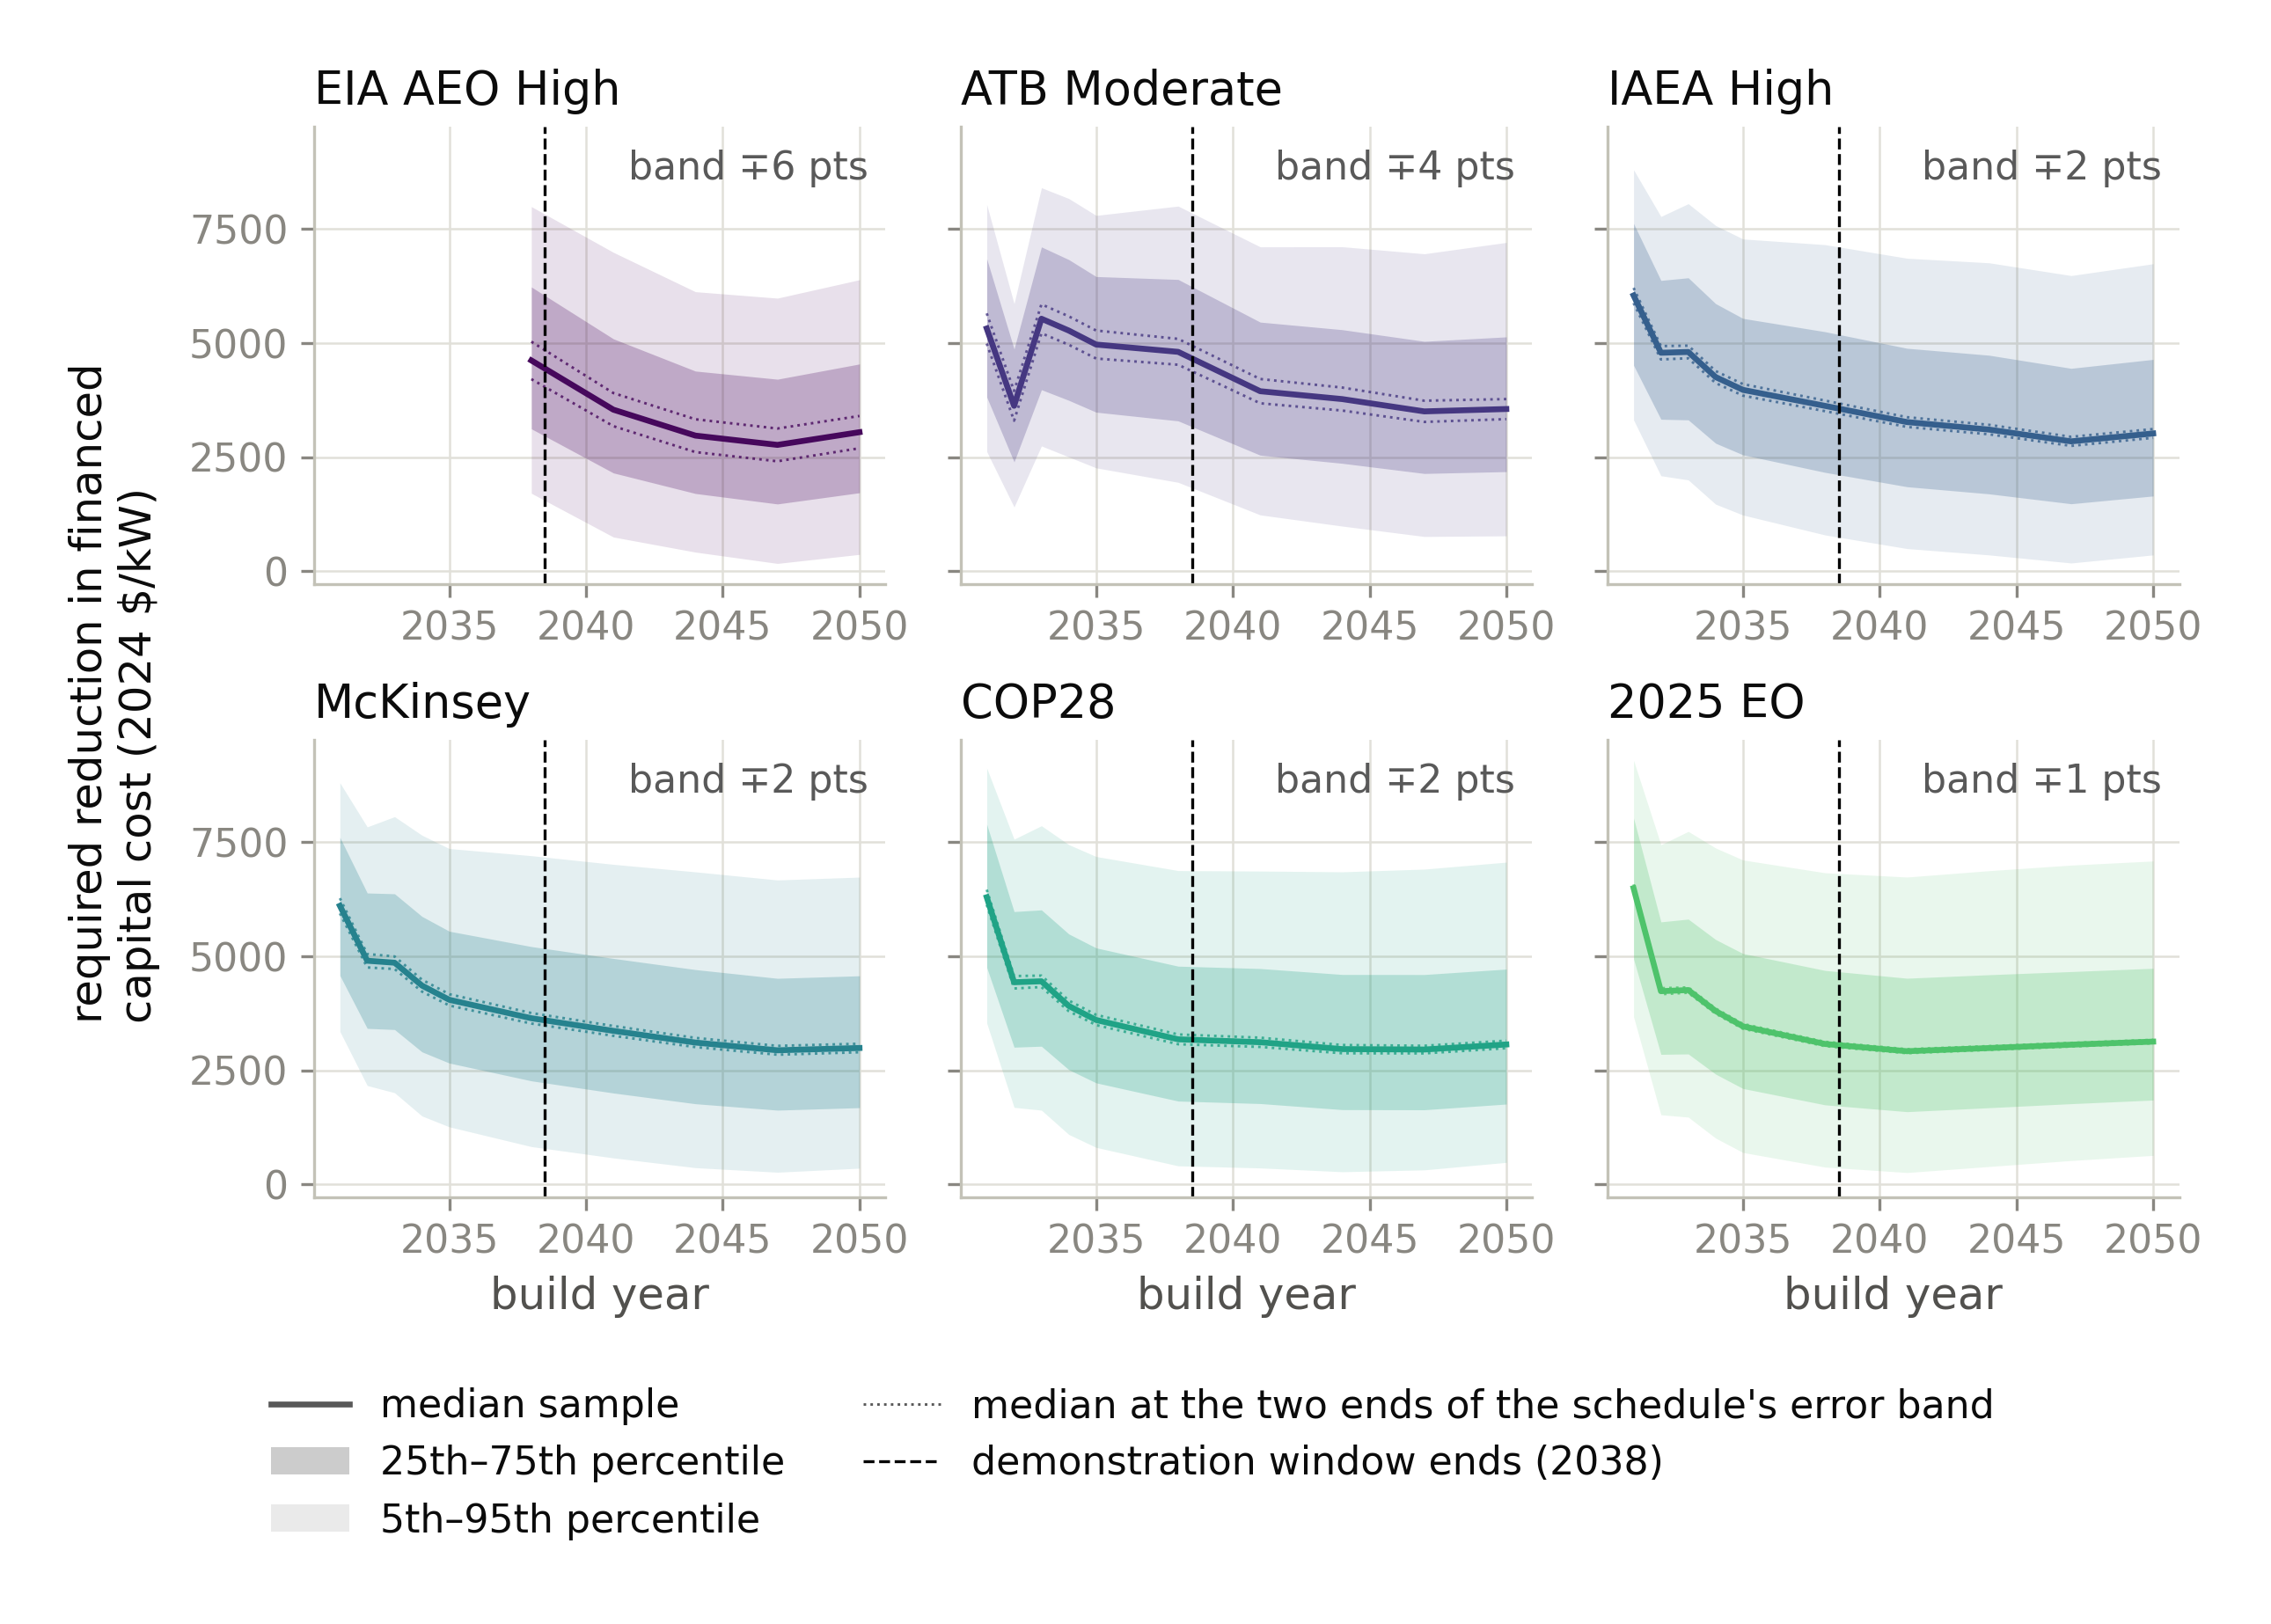

saved -> analysis\results\exports\10\n105_rate_fans_pct.png


saved -> analysis\results\exports\10\n106_mask_paper.png


saved -> analysis\results\figures\si\SF22_demonstration_gap.png
SF21, SF22 and the Fig. 4 sources written


In [17]:
def _clip_spans(ts, top, lim=1.0):
    ts, top = np.asarray(ts, float), np.asarray(top, float)
    spans, x0 = [], None
    for j in range(len(ts)):
        if top[j] > lim and x0 is None:
            x0 = ts[j] if j == 0 else ts[j-1] + (lim - top[j-1]) / (top[j] - top[j-1]) * (ts[j] - ts[j-1])
        elif top[j] <= lim and x0 is not None:
            spans.append((x0, ts[j-1] + (lim - top[j-1]) / (top[j] - top[j-1]) * (ts[j] - ts[j-1])))
            x0 = None
    if x0 is not None:
        spans.append((x0, ts[-1]))
    return spans

# 09-24 (E11, SI type pass): PAPER_FONT scaled to this figure's rendered canvas, so the
# type PRINTS at the specification once _build_si_doc.py places the image 6.5 in wide.
SIF_CW_N104 = 8.62
def dollar_fans(tbl, name):
    SIF_D = ps.fonts(SIF_CW_N104)
    fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.0), sharey=True)
    for ax, ab in zip(axes.flat, SCHEDULES):
        sub = tbl[(tbl["schedule"] == ab) & (tbl["band"] == "base") & (tbl["quantity"] == "need_kw")]
        ts = sub["year"].to_numpy()
        ax.fill_between(ts, sub["p05"], sub["p95"], color=ps.SCHED_C[ab], alpha=0.12, lw=0)
        ax.fill_between(ts, sub["p25"], sub["p75"], color=ps.SCHED_C[ab], alpha=0.25, lw=0)
        ax.plot(ts, sub["p50"], color=ps.SCHED_C[ab], lw=1.6)
        for bnd in ["lo", "hi"]:
            sb = tbl[(tbl["schedule"] == ab) & (tbl["band"] == bnd) & (tbl["quantity"] == "need_kw")]
            ax.plot(sb["year"], sb["p50"], color=ps.SCHED_C[ab], lw=0.7, ls=":", alpha=0.8)
        ax.axvline(W_COMMON + 0.5, color="k", lw=0.8, ls="--")
        ax.set_title(ps.SCHED_SHORT[ab], fontsize=SIF_D["panel_title"])
        ax.set_xlim(MODEL_YEARS[0] - 0.95, MODEL_YEARS[-1] + 0.95)   # 09-18: one build-year axis for every schedule (EIA starts in 2038)
        ax.text(0.97, 0.95, f"band ∓{E7_PTS[ab]} pts", transform=ax.transAxes, fontsize=SIF_D["annotation"], ha="right", va="top", color=GREY)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.tick_params(labelsize=SIF_D["tick"])
    for ax in axes[1]:
        ax.set_xlabel("build year", fontsize=SIF_D["axis_label"])
    # 09-24: one shared y label. At the new size two lines of a 29-character label were taller
    # than the panel and ran off the figure's left edge; sharey already makes it one axis.
    fig.supylabel("required reduction in financed\ncapital cost (2024 $/kW)", fontsize=SIF_D["axis_label"])
    handles = [Line2D([], [], color=GREY, lw=1.6, label="median sample"),
               Patch(facecolor=GREY, alpha=0.30, label="25th–75th percentile"),
               Patch(facecolor=GREY, alpha=0.12, label="5th–95th percentile"),
               Line2D([], [], color=GREY, lw=0.7, ls=":", label="median at the two ends of the schedule's error band"),
               Line2D([], [], color="k", lw=0.8, ls="--", label=f"demonstration window ends ({W_COMMON})")]
    fig.tight_layout()
    fig.legend(handles=handles, ncol=2, fontsize=SIF_D["legend"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0))
    ps.savefig(fig, EXPORTS / name)
    plt.close(fig)

dollar_fans(m104c, "n104_dollar_fans_cut.png")       # the display twin; SF21 is this panel, unlettered
compose.compose([[EXPORTS / "n104_dollar_fans_cut.png"]], "SF21_credit_denominated_gap.png", letters="", out_dir=paths.FIGS_SI)

# n105: the rate fans in percent, display twin, clipped at 100% (main Fig 4a); sharex (09-18): the EIA panel on the common axis
PF = ps.fonts(ps.PAPER_CANVAS_IN["fig4"])                 # 09-24 (E11): one type spec for every main figure
fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.0), sharey=True)
for ax, ab in zip(axes.flat, SCHEDULES):
    sub = m104c[(m104c["schedule"] == ab) & (m104c["band"] == "base") & (m104c["quantity"] == "rate")]
    ts = sub["year"].to_numpy()
    ax.fill_between(ts, sub["p05"], sub["p95"], color=ps.SCHED_C[ab], alpha=0.12, lw=0)
    ax.fill_between(ts, sub["p25"], sub["p75"], color=ps.SCHED_C[ab], alpha=0.25, lw=0)
    ax.plot(ts, sub["p50"], color=ps.SCHED_C[ab], lw=1.6)
    ax.axhline(CAPS[0], color=ps.ACCENT["red"], lw=0.9, ls=":")   # 09-23 (C20): no error-band medians and no 60% ceiling marker
    ax.set_ylim(0.0, 1.0)
    for x0, x1 in _clip_spans(ts, sub["p95"]):
        if x1 - x0 < 1.0:
            x0, x1 = x1 - 1.0, x1
        ax.plot([x0, x1], [1.0, 1.0], color=ps.ACCENT["red"], lw=2.4, solid_capstyle="butt", clip_on=False, zorder=6)
    ax.set_title(ps.SCHED_LABEL[ab], fontsize=PF["panel_title"])   # 09-23 (C14/C20/C21): capitalized target name with its 2050 amount
    ax.set_xlim(MODEL_YEARS[0] - 0.95, MODEL_YEARS[-1] + 0.95)   # 09-18: one online-year axis for every schedule (EIA starts in 2038)
    # 09-24 (Ethan F2): the band is symmetric, so the sign is ±, and one point is "pt"
    _e7 = E7_PTS[ab]
    ax.text(0.97, 0.95, f"error ±{_e7} pt" + ("" if _e7 == 1 else "s"), transform=ax.transAxes,
            fontsize=PF["annotation"], ha="right", va="top", color=GREY)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.tick_params(labelsize=PF["tick"])
for ax in axes[1]:
    ax.set_xlabel("Online Year", fontsize=PF["axis_label"])
for ax in axes[:, 0]:
    ax.set_ylabel("Equivalent ITC (%)", fontsize=PF["axis_label"])     # 09-23 (C20): the required credit rate, named as the paper names it
handles = [Line2D([], [], color=GREY, lw=1.6, label="median"),
           Patch(facecolor=GREY, alpha=0.30, label="25th–75th percentile"),
           Patch(facecolor=GREY, alpha=0.12, label="5th–95th percentile"),
           Line2D([], [], color=ps.ACCENT["red"], lw=0.9, ls=":", label="current statutory maximum 50%")]
fig.tight_layout()
fig.legend(handles=handles, ncol=3, fontsize=PF["legend"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0))
ps.savefig(fig, EXPORTS / "n105_rate_fans_pct.png")
plt.close(fig)

# n106: share of samples credit-feasible from each year on at the 50% cap, display twin (main Fig 4b; v2.9.1 cumulative)
PF = ps.fonts(ps.PAPER_CANVAS_IN["fig4"])                 # 09-24 (E11): one type spec for every main figure
# 09-24 (Ethan F2): the axes take about two thirds of the composed figure width and the
# legend sits beside them instead of underneath.
fig, ax = plt.subplots(figsize=(8.4, 2.9))   # 09-23c: five-year ticks
_ends = {}
for ab in SCHEDULES:
    sub = m105c[(m105c["schedule"] == ab) & (m105c["band"] == "base") & (m105c["cap"] == 0.50)].sort_values("year")
    cov_ = (1.0 - sub["share_above_from"].to_numpy()) * 100          # v2.9.1: credit-feasible from this year on
    ax.plot(sub["year"], cov_, color=ps.SCHED_C[ab], lw=1.5, label=ps.SCHED_LABEL[ab])
    _ends[ab] = (float(sub["year"].iloc[-1]), float(cov_[-1]))
_order = sorted(_ends, key=lambda a: _ends[a][1])
_ys = [_ends[a][1] for a in _order]
for i in range(1, len(_ys)):
    _ys[i] = max(_ys[i], _ys[i - 1] + 8.0)   # 09-24: one line of the label type, on the shorter panel
_ys = [y - max(_ys[-1] - 100.0, 0.0) for y in _ys]
for ab, y in zip(_order, _ys):
    x_end, v = _ends[ab]
    ax.annotate(f"{v:.0f}%", xy=(x_end, v), xytext=(x_end + 0.5, y), textcoords="data", fontsize=PF["annotation"],
                color=ps.SCHED_C[ab], va="center", ha="left",
                arrowprops=dict(arrowstyle="-", color=ps.SCHED_C[ab], lw=0.4, alpha=0.6, shrinkA=0, shrinkB=1))
ax.set_xlabel("Online Year", fontsize=PF["axis_label"])               # 09-23 (C20): no demonstration-window marker on either panel
ax.set_ylabel("Share of Samples\nCredit-Feasible from\nThat Year On,\n50% Cap (%)", fontsize=PF["axis_label"])
ax.set_ylim(0, 100)
ax.set_xlim(right=max(v[0] for v in _ends.values()) + 3.5)
ax.set_xticks(list(range(2035, 2051, 5)))                  # 09-23c: five-year ticks (the 3-year set overlapped)
ax.tick_params(labelsize=PF["tick"])
ax.legend(fontsize=PF["legend"], frameon=False, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(rect=(0, 0, 0.70, 1))   # 09-24: the right third is the legend's
ps.savefig(fig, EXPORTS / "n106_mask_paper.png")
plt.close(fig)

# n107: the demonstration funding requirement through the common window, display twin (main Fig 4c)
# 09-24 (E11, SI type pass): PAPER_FONT scaled to this figure's rendered canvas, so the
# type PRINTS at the specification once _build_si_doc.py places the image 6.5 in wide.
SIF_CW_N107 = 4.01
SIF_G = ps.fonts(SIF_CW_N107)
fig, ax = plt.subplots(figsize=(4.1, 3.4))
xpos = np.arange(len(SCHEDULES))
for cap, off, al in [(0.50, -0.17, 0.55), (0.60, 0.17, 1.0)]:
    sub = m106c[(m106c["band"] == "base") & (m106c["window"] == "w2038") & (m106c["cap"] == cap)].set_index("schedule").reindex(SCHEDULES)
    ax.bar(xpos + off, sub["gap_p95_B"], width=0.3, alpha=al * 0.35, color=[ps.SCHED_C[ab] for ab in SCHEDULES])
    ax.bar(xpos + off, sub["gap_p50_B"], width=0.3, alpha=al, color=[ps.SCHED_C[ab] for ab in SCHEDULES])
ax.set_xticks(xpos, [ps.SCHED_SHORT[ab] for ab in SCHEDULES], fontsize=SIF_G["tick"], rotation=25, ha="right")
ax.set_ylabel("demonstration funding requirement\n(2024 $B)", fontsize=SIF_G["axis_label"])
ax.tick_params(axis="y", labelsize=SIF_G["tick"])
ax.legend(handles=[Patch(facecolor=GREY, alpha=0.55, label="left bar: 50% cap"),
                   Patch(facecolor=GREY, alpha=1.0, label="right bar: 60% cap"),
                   Patch(facecolor=GREY, alpha=0.35, label="faint: expensive sample (P95)"),
                   Patch(facecolor=GREY, alpha=1.0, label="solid: median sample")],
          fontsize=SIF_G["legend"], frameon=False, loc="upper left")
fig.tight_layout()
ps.savefig(fig, paths.FIGS_SI / "SF22_demonstration_gap.png")
plt.close(fig)

print("SF21, SF22 and the Fig. 4 sources written")

## 15. Figure: the Fig. 3 source (n104c)

The predicted shadow-price fans of `m104c`, converted at the point of display from 2024 to 2025
dollars with `ps.to2025(2024)`; the export stays in 2024 dollars.

In [18]:
# n104c -- main Fig 3 (methods v2.8.3): the predicted shadow price S fanned across the samples; no cushion, no band; sharex (09-18): the EIA panel on the common axis
# 2026-09-23 (C14, Ethan): "median" not "median sample"; no demonstration-window marker; x label "Online Year"; panel
# titles carry the capitalized target name with its 2050 amount. The paper reports 2025 dollars, so the plotted values
# are converted here with plotstyle.to2025(2024); the export m104c_shadow_price_fans.csv stays in 2024 dollars.
TO25 = ps.to2025(2024)                                    # 2024$ -> 2025$, from inputs/financials/deflator.csv
U25 = ps.usd("kW", ps.PAPER_DOLLAR_YEAR)[1:-1]            # "2025$/kW" without the parentheses
PF = ps.fonts(ps.PAPER_CANVAS_IN["fig3"])                 # 09-24 (E11): one type spec for every main figure
fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.0), sharey=True)
for ax, ab in zip(axes.flat, SCHEDULES):
    sub = m104s[m104s["schedule"] == ab].sort_values("year")
    ts = sub["year"].to_numpy()
    ax.fill_between(ts, sub["p05"] * TO25, sub["p95"] * TO25, color=ps.SCHED_C[ab], alpha=0.12, lw=0)
    ax.fill_between(ts, sub["p25"] * TO25, sub["p75"] * TO25, color=ps.SCHED_C[ab], alpha=0.25, lw=0)
    ax.plot(ts, sub["p50"] * TO25, color=ps.SCHED_C[ab], lw=1.6)
    ax.set_title(ps.SCHED_LABEL[ab], fontsize=PF["panel_title"])
    ax.set_xlim(MODEL_YEARS[0] - 0.95, MODEL_YEARS[-1] + 0.95)   # 09-18: one online-year axis for every schedule (EIA starts in 2038)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.tick_params(labelsize=PF["tick"])
for ax in axes[1]:
    ax.set_xlabel("Online Year", fontsize=PF["axis_label"])
for ax in axes[:, 0]:
    ax.set_ylabel(f"Required Support\n({U25},\nFinanced Basis)", fontsize=PF["axis_label"])
handles = [Line2D([], [], color=GREY, lw=1.6, label="median"),
           Patch(facecolor=GREY, alpha=0.30, label="25th–75th percentile"),
           Patch(facecolor=GREY, alpha=0.12, label="5th–95th percentile")]
fig.tight_layout()
fig.legend(handles=handles, ncol=3, fontsize=PF["legend"], frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0))
ps.savefig(fig, EXPORTS / "n104c_shadow_price_fans.png")
plt.close(fig)
print(f"n104c written in 2025 dollars (x{TO25:.4f} on the 2024$ export)")

saved -> analysis\results\exports\10\n104c_shadow_price_fans.png
n104c written in 2025 dollars (x1.0260 on the 2024$ export)


## 16. The verdict rows (m108) and the run record

`m108` collects every gate, band, kill test and record line this notebook produced, one row each
(Supplementary Note 5 cites it). Notebooks 11, 15 and 16 read its `map-basis`, `KB1` and `KB2` rows.
`requirement_map_metadata.json` records the chosen member, the bands and the fit numbers.

In [19]:
m108 = pd.DataFrame(VERDICT, columns=["kind", "name", "result", "detail"])
m108.to_csv(EXPORTS / "m108_verdict.csv", index=False)
print(m108.to_string(index=False))
meta = {"notebook": "10_requirement_map.ipynb", "registration": "methods register v2.9 (2026-09-18; on v2.8 + v2.8.1 + v2.8.2 + v2.8.3)",
        "chosen_family": CHOSEN, "target": "S_kw", "conversion": "own_ccmult", "inputs": ["occ_k", "ct_yrs", "fom", "ct_x_occ"],
        "n_features": len(MODEL.cols), "n_family": len(FAM6), "E7_pts": E7_PTS, "E7_level": E7_LEVEL, "GM1": GM1,
        "GM2": "PASS" if GM2 else "FAIL", "lambda_boundary_hit": BOUNDARY_HIT, "pooled_mae": P_CH["mae"], "pooled_p90": P_CH["p90"],
        "p90_weighted": P_CH["p90_weighted"], "nested_mae": NESTED["mae"], "mae_native_kw": P_CH["mae_native"],
        "display_cut": DISPLAY_CUT, "w_common": W_COMMON, "discount_rate": DR, "n_anchors": 66, "n_cells": N_FIT,
        "n_over100_cells_in_fit": len(CENS_CELLS), "split_design": "exhaustive C(11,2)"}
(EXPORTS / "requirement_map_metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("metadata written")

  kind               name                                                                           result                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                detail
  gate                 G3                                                                             PASS                                                                                                                                             